
<h1 style="text-align: center;"><strong>Data Science & Statistical Computing</strong></h1>
<h2 style="text-align: center;"><strong>CHALLENGE - TOTVS</strong></h2>
<h4 style="text-align: center;"><strong>FIAP - 2026</strong></h4>
<br>
<br>

# **Integrantes**

**Jéssica Domingues** — RM 562973  
**Kauã Carvalho De Oliveira** — RM 566371  
**João Vitor Piccolo** — RM 565127  
**Leonardo Lopes** — RM 561349  
**Gabrielle Calazans** — RM 564460

## Parte 1 — Setup e dados

In [ ]:
# Configurações gerais
SEED = 42

import os
import json
import re
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report


np.random.seed(SEED)
sns.set_theme(style="whitegrid")

In [ ]:
# Parâmetros do arquivo e das colunas
DATA_FILE_NAME = "ANON_transcricao.json"

TEXT_COLUMN = "ANON_TRANSCRICAO"
TARGET_COLUMN = "NOTA_NPS"

# Classificação BINÁRIA: Negativo (Detrator, notas 0-6) x Positivo (Promotor, notas 9-10).
# Notas 7 e 8 (Neutro) sao excluidas do treino/avaliacao supervisionados
LABEL2ID = {"Negativo": 0, "Positivo": 1}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

NOTA_LIMIAR_DETRATOR = 6
NOTA_LIMIAR_PROMOTOR = 9

HOLDOUT_SIZE = 0.20
N_FOLDS = 5

METADATA_COLS = [
    "NOME_SEGMENTO", "UF", "FAIXA_FATURAMENTO_CLIENTE_EC", "CNAE",
    "TP_RECURSO", "NOME_UNIDADE", "DURACAO_MEETING", "FORMATO_MEETING",
]

In [ ]:
def localizar_arquivo_dados(nome_arquivo: str) -> Path:
    """Procura o arquivo de dados no diretório atual; se não achar pelo nome
    exato, tenta localizar um único .json/.jsonl candidato."""
    caminho = Path.cwd() / nome_arquivo
    if caminho.exists():
        return caminho

    candidatos = sorted(list(Path.cwd().glob("*.json")) + list(Path.cwd().glob("*.jsonl")))
    if len(candidatos) == 1:
        print(f"Arquivo '{nome_arquivo}' não encontrado. Usando: {candidatos[0].name}")
        return candidatos[0]
    if len(candidatos) > 1:
        nomes = "\n".join(f"- {c.name}" for c in candidatos)
        raise FileNotFoundError(
            f"Arquivo '{nome_arquivo}' não encontrado e há múltiplos candidatos:\n{nomes}"
        )
    raise FileNotFoundError(f"Nenhum arquivo de dados encontrado em {Path.cwd()}")


def ler_dados_jsonl(caminho: Path) -> pd.DataFrame:
    """Lê o arquivo linha a linha (1 objeto JSON por linha) — mais robusto que
    json.load direto, pois o arquivo não é uma lista JSON única."""
    registros = []
    with open(caminho, "r", encoding="utf-8") as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            registros.append(json.loads(linha))
    return pd.DataFrame(registros)

In [ ]:
caminho_dados = localizar_arquivo_dados(DATA_FILE_NAME)
df = ler_dados_jsonl(caminho_dados)

print(f"Dimensão da base: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
display(df.info())
display(df.head(3))

Dimensão da base: 1174 linhas e 18 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1174 entries, 0 to 1173
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   ID_MEETING                    1174 non-null   object
 1   DT_MEETING                    1174 non-null   object
 2   FORMATO_MEETING               1174 non-null   object
 3   ID_STATUS_MEETING             1174 non-null   object
 4   STATUS_MEETING                1174 non-null   object
 5   DURACAO_MEETING               1174 non-null   object
 6   CODT                          1174 non-null   object
 7   FLG_EXTERNO                   1174 non-null   bool  
 8   DT_CRIACAO                    1174 non-null   object
 9   ANON_TRANSCRICAO              1174 non-null   object
 10  UF                            752 non-null    object
 11  CNAE                          752 non-null    object
 12  NOME_UNIDADE                  75

None

,ID_MEETING,DT_MEETING,FORMATO_MEETING,ID_STATUS_MEETING,STATUS_MEETING,DURACAO_MEETING,CODT,FLG_EXTERNO,DT_CRIACAO,ANON_TRANSCRICAO,UF,CNAE,NOME_UNIDADE,NOME_SEGMENTO,FAIXA_FATURAMENTO_CLIENTE_EC,DT_ULTIMA_PESQUISA,NOTA_NPS,TP_RECURSO
0,1247082,2026-03-18 16:00:00,VIDEO,3,COMPLETED,01:39:13,T27261,True,2026-03-13 16:47:22,"[LOCUTOR 102]: [PESSOA], boa tarde.\n[LOCUTOR ...",DF,8610102,TOTVS SAUDE,SAUDE,06.SMB III - De R$ 120.000.001 a R$ 240.000.000,NaN,NaN,NaN
1,989351,2026-01-28 15:30:00,VIDEO,3,COMPLETED,01:07:12,T27261,True,2026-01-28 10:27:10,[LOCUTOR 2]: Obrigado.\n[LOCUTOR 28]: E\n[LOCU...,DF,8610102,TOTVS SAUDE,SAUDE,06.SMB III - De R$ 120.000.001 a R$ 240.000.000,NaN,NaN,NaN
2,1027294,2026-02-11 14:00:00,VIDEO,3,COMPLETED,02:28:38,CXHNWJ,True,2026-02-04 14:07:52,"[LOCUTOR 107]: [EMPRESA], [PESSOA], tudo bem?\...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Quantos registros têm nota de NPS preenchida?
def nota_valida(v):
    return v not in (None, "", "null") and not (isinstance(v, float) and pd.isna(v))

df[TARGET_COLUMN] = df[TARGET_COLUMN].where(df[TARGET_COLUMN].apply(nota_valida), None)
tem_nota = df[TARGET_COLUMN].notna()

print(f"Com NOTA_NPS preenchida : {tem_nota.sum()}")
print(f"Sem NOTA_NPS (candidatos a pseudo-rotulação): {(~tem_nota).sum()}")

Com NOTA_NPS preenchida : 311
Sem NOTA_NPS (candidatos a pseudo-rotulação): 863


### EDA rápida

Distribuição das notas reais, tamanho das transcrições e alguns cruzamentos com metadados
do cliente/reunião. Serve para entender desbalanceamento de classes e outliers de tamanho
antes de definir os parâmetros do TF-IDF (evita que transcrições muito longas dominem o
vocabulário do vetorizador).

count     1174.000000
mean      6852.022147
std       4706.133808
min         63.000000
25%       3376.750000
50%       6005.000000
75%       9324.500000
max      31105.000000
Name: ANON_TRANSCRICAO, dtype: float64


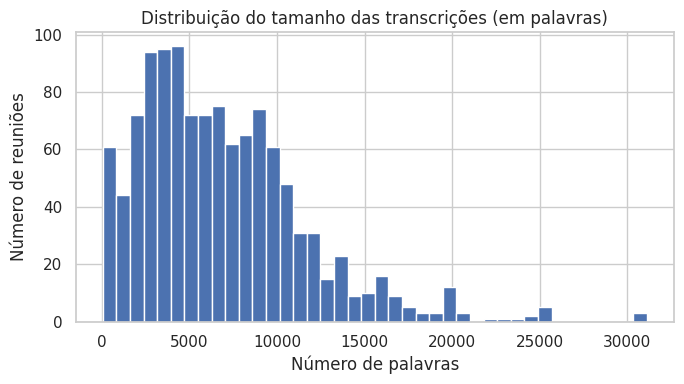

In [ ]:
n_palavras = df[TEXT_COLUMN].fillna("").astype(str).str.split().str.len()
print(n_palavras.describe())

fig, ax = plt.subplots(figsize=(7, 4))
n_palavras.plot(kind="hist", bins=40, ax=ax, color="#4C72B0")
ax.set_title("Distribuição do tamanho das transcrições (em palavras)")
ax.set_xlabel("Número de palavras")
ax.set_ylabel("Número de reuniões")
plt.tight_layout()
plt.show()

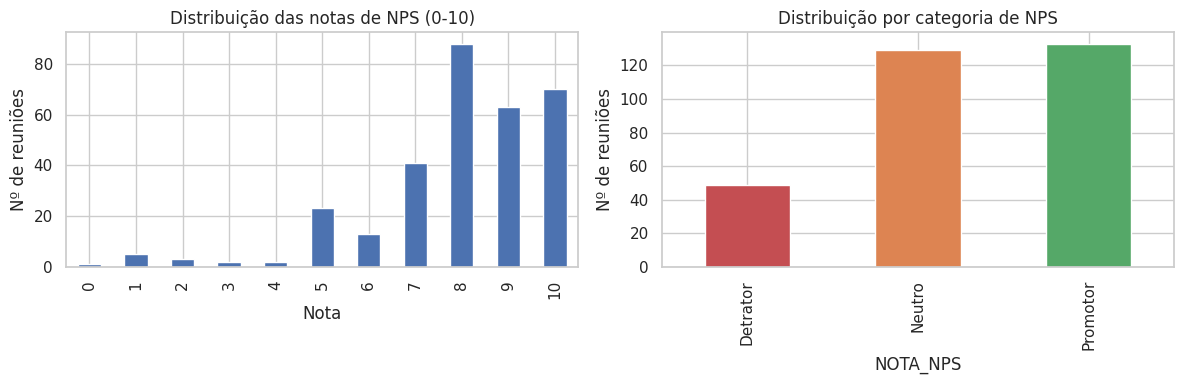

NOTA_NPS
Promotor    133
Neutro      129
Detrator     49
Name: count, dtype: int64


In [ ]:
notas_validas = df.loc[tem_nota, TARGET_COLUMN].astype(float).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
notas_validas.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição das notas de NPS (0-10)")
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("Nº de reuniões")

def nota_para_categoria(valor):
    if valor is None or (isinstance(valor, float) and pd.isna(valor)):
        return None
    nota = int(float(valor))
    if nota <= 6:
        return "Detrator"
    elif nota <= 8:
        return "Neutro"
    return "Promotor"

categorias_validas = notas_validas.apply(nota_para_categoria)
categorias_validas.value_counts().reindex(["Detrator", "Neutro", "Promotor"]).plot(
    kind="bar", ax=axes[1], color=["#C44E52", "#DD8452", "#55A868"]
)
axes[1].set_title("Distribuição por categoria de NPS")
axes[1].set_ylabel("Nº de reuniões")
plt.tight_layout()
plt.show()

print(categorias_validas.value_counts())

Distribuição original (3 vias):
NOTA_NPS
Detrator     49
Neutro      129
Promotor    133
Name: count, dtype: int64

Após excluir Neutros (notas 7-8):
  Ficam para treino/avaliação binária : 182 registros
  Excluídos (Neutro)                  : 129 registros (41.5% dos rotulados)


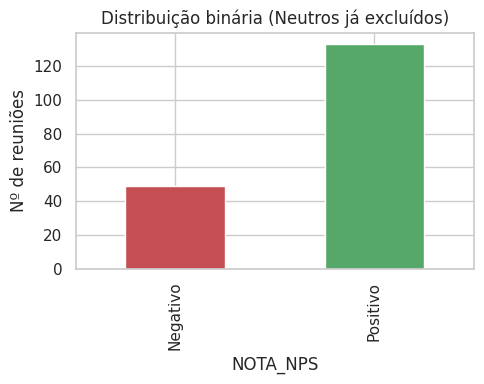

In [ ]:
def nota_para_polaridade(valor):
    if valor is None or (isinstance(valor, float) and pd.isna(valor)):
        return None
    nota = int(float(valor))
    if nota <= NOTA_LIMIAR_DETRATOR:
        return "Negativo"
    elif nota >= NOTA_LIMIAR_PROMOTOR:
        return "Positivo"
    return None


polaridade_validas = notas_validas.apply(nota_para_polaridade)
n_neutros_excluidos = polaridade_validas.isna().sum()
n_binario = polaridade_validas.notna().sum()

print("Distribuição original (3 vias):")
print(categorias_validas.value_counts().reindex(["Detrator", "Neutro", "Promotor"]))
print(f"\nApós excluir Neutros (notas 7-8):")
print(f"  Ficam para treino/avaliação binária : {n_binario} registros")
print(f"  Excluídos (Neutro)                  : {n_neutros_excluidos} registros "
      f"({n_neutros_excluidos / len(notas_validas):.1%} dos rotulados)")

fig, ax = plt.subplots(figsize=(5, 4))
polaridade_validas.value_counts().reindex(["Negativo", "Positivo"]).plot(
    kind="bar", ax=ax, color=["#C44E52", "#55A868"]
)
ax.set_title("Distribuição binária (Neutros já excluídos)")
ax.set_ylabel("Nº de reuniões")
plt.tight_layout()
plt.show()

### Limpeza de texto

Remove as tags `[LOCUTOR N]:` (identificação de quem fala, não carrega sinal de sentimento)
e normaliza espaços/pontuação repetida. As tags de anonimização (`[PESSOA]`, `[EMPRESA]`,
`[LOCAL]`) são mantidas como estão — já vêm anonimizadas na fonte.

In [ ]:
TAG_LOCUTOR = re.compile(r"\[LOCUTOR\s*\d+\]:\s*")
ESPACOS_MULTIPLOS = re.compile(r"\s+")
PONTUACAO_REPETIDA = re.compile(r"([!?.,])\1{1,}")

def limpar_transcricao(texto: str) -> str:
    texto = str(texto) if texto is not None else ""
    sem_tags = TAG_LOCUTOR.sub(" ", texto)
    sem_pontuacao_repetida = PONTUACAO_REPETIDA.sub(r"\1", sem_tags)
    return ESPACOS_MULTIPLOS.sub(" ", sem_pontuacao_repetida).strip()

df["TEXTO_LIMPO"] = df[TEXT_COLUMN].apply(limpar_transcricao)

print("Antes:\n", df[TEXT_COLUMN].iloc[0][:300], "\n")
print("Depois:\n", df["TEXTO_LIMPO"].iloc[0][:300])

Antes:
 [LOCUTOR 102]: [PESSOA], boa tarde.
[LOCUTOR 49]: [EMPRESA], boa tarde. Tudo bem, [PESSOA], [PESSOA]?
[LOCUTOR 102]: Boa tarde, [PESSOA].
[LOCUTOR 49]: Tudo bem?
[LOCUTOR 102]: Eu penso que o [PESSOA] deve estar numa ligação,
[LOCUTOR 49]: porque
[LOCUTOR 102]: o telefone estava aberto.
[LOCUTOR 49] 

Depois:
 [PESSOA], boa tarde. [EMPRESA], boa tarde. Tudo bem, [PESSOA], [PESSOA]? Boa tarde, [PESSOA]. Tudo bem? Eu penso que o [PESSOA] deve estar numa ligação, porque o telefone estava aberto. alguém conversando com ele. Tá bom. tarde. [EMPRESA], [PESSOA], tudo bem? Tudo bem, vocês? Tudo ótimo. Estava fala


### Definição do target e split rotulado / não rotulado

Aplica o mesmo threshold de NPS usado na EDA e separa os dois universos:
* `df_rotulado` — os registros com nota real (vão alimentar o baseline, a comparação de modelos e o self-training)
* `df_nao_rotulado` — os 863 sem nota (candidatos à pseudo-rotulação via self-training)


In [ ]:
# Categoria de 3 vias fica só como referência/EDA; a categoria BINÁRIA é o alvo real.
df["NPS_CATEGORIA_3VIAS"] = df[TARGET_COLUMN].apply(nota_para_categoria)
df["NPS_CATEGORIA"] = df[TARGET_COLUMN].apply(nota_para_polaridade)   # Negativo / Positivo / None
df["label_id"] = df["NPS_CATEGORIA"].map(LABEL2ID)

tem_nota_valida = df[TARGET_COLUMN].apply(nota_valida)

df_rotulado = df[tem_nota_valida & df["NPS_CATEGORIA"].notna()].reset_index(drop=True)
df_neutros = df[tem_nota_valida & df["NPS_CATEGORIA"].isna()].reset_index(drop=True)
df_nao_rotulado = df[~tem_nota_valida].reset_index(drop=True)

print(f"Rotulados binário (Negativo/Positivo): {len(df_rotulado)}")
print(f"Neutros excluídos (notas 7 e 8): {len(df_neutros)}")
print(f"Não rotulados (candidatos a pseudo-label): {len(df_nao_rotulado)}")
display(df_rotulado["NPS_CATEGORIA"].value_counts())

Rotulados binário (Negativo/Positivo): 182
Neutros excluídos (notas 7 e 8): 129
Não rotulados (candidatos a pseudo-label): 863


,count
NPS_CATEGORIA,
Positivo,133
Negativo,49


### Hold-out cego

Reserva uma fatia estratificada dos rotulados reais que **não entra em nenhuma etapa
de treino ou self-training** — serve exclusivamente para a avaliação final, comparando
o baseline, o modelo treinado só com dados reais e o modelo treinado com a base ampliada
(self-training + revisão humana). Sem isso, qualquer ganho reportado pelo self-training seria
inconclusivo (poderia ser o próprio modelo "vazando" para a avaliação através dos
pseudo-rótulos).


In [ ]:
df_treino_rotulado, df_holdout = train_test_split(
    df_rotulado,
    test_size=HOLDOUT_SIZE,
    stratify=df_rotulado["NPS_CATEGORIA"],
    random_state=SEED,
)
df_treino_rotulado = df_treino_rotulado.reset_index(drop=True)
df_holdout = df_holdout.reset_index(drop=True)

print(f"Treino rotulado (usado em CV, comparação de modelos e self-training): {len(df_treino_rotulado)}")
print(f"Hold-out cego (só avaliação final): {len(df_holdout)}")
display(df_treino_rotulado["NPS_CATEGORIA"].value_counts())
display(df_holdout["NPS_CATEGORIA"].value_counts())


Treino rotulado (usado em CV, comparação de modelos e self-training): 145
Hold-out cego (só avaliação final): 37


,count
NPS_CATEGORIA,
Positivo,106
Negativo,39


,count
NPS_CATEGORIA,
Positivo,27
Negativo,10


## Parte 2 — Baseline supervisionado (TF-IDF + Regressão Logística)



In [ ]:
try:
    from stop_words import get_stop_words
    STOPWORDS_PT = set(get_stop_words("portuguese"))
except Exception:
    # fallback minimalista caso o pacote stop_words não esteja instalado
    STOPWORDS_PT = {
        "a","o","as","os","de","da","do","das","dos","em","um","uma","uns","umas",
        "e","é","ou","para","por","com","que","se","na","no","nas","nos","como",
        "mais","mas","ao","aos","à","às","já","também","muito","foi","ser","está",
    }

# Preserva negações
NEGACOES_PRESERVADAS = {"não", "nao", "nem", "nunca", "jamais", "tampouco", "nenhum", "nenhuma", "nada", "ninguém"}
STOPWORDS_PT -= NEGACOES_PRESERVADAS

print(f"Stopwords carregadas: {len(STOPWORDS_PT)} (negações preservadas: {sorted(NEGACOES_PRESERVADAS)})")

TOKEN_PATTERN = re.compile(r"[A-Za-zÀ-ÖØ-öø-ÿ]+(?:[-'][A-Za-zÀ-ÖØ-öø-ÿ]+)*")

def tokenizar_sem_stopwords(texto: str):
    tokens = TOKEN_PATTERN.findall(texto.lower())
    return [t for t in tokens if t not in STOPWORDS_PT and len(t) > 1]

Stopwords carregadas: 39 (negações preservadas: ['jamais', 'nada', 'nao', 'nem', 'nenhum', 'nenhuma', 'ninguém', 'nunca', 'não', 'tampouco'])


In [ ]:
MAX_FEATURES = 500
MIN_DF = 5
C_LOGREG = 0.5

X_texto = df_treino_rotulado["TEXTO_LIMPO"].values
y = df_treino_rotulado["label_id"].values

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

resultados_baseline = []
matriz_confusao_baseline = np.zeros((3, 3), dtype=int)

for fold, (idx_treino, idx_val) in enumerate(skf.split(X_texto, y)):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(
            tokenizer=tokenizar_sem_stopwords,
            lowercase=True,
            max_features=MAX_FEATURES,
            min_df=MIN_DF,
            ngram_range=(1, 2),
            token_pattern=None,
        )),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=C_LOGREG, random_state=SEED)),
    ])

    pipe.fit(X_texto[idx_treino], y[idx_treino])
    preds_treino = pipe.predict(X_texto[idx_treino])
    preds_val = pipe.predict(X_texto[idx_val])

    acc_treino = accuracy_score(y[idx_treino], preds_treino)
    acc = accuracy_score(y[idx_val], preds_val)
    f1_macro = f1_score(y[idx_val], preds_val, average="macro")
    resultados_baseline.append({
        "fold": fold, "acc_treino": acc_treino, "acc": acc, "f1_macro": f1_macro,
        "gap_treino_val": acc_treino - acc,
    })
    matriz_confusao_baseline += confusion_matrix(y[idx_val], preds_val, labels=[0, 1, 2])

    print(f"Fold {fold}: acc_treino={acc_treino:.3f} | acc_val={acc:.3f} | f1_macro={f1_macro:.3f} "
          f"| gap={acc_treino - acc:.3f}")

df_baseline = pd.DataFrame(resultados_baseline)
print("\nMédia CV (o gap treino-validação é o sinal de overfitting a observar aqui):")
display(df_baseline[["acc_treino", "acc", "f1_macro", "gap_treino_val"]].mean())

Fold 0: acc_treino=0.741 | acc_val=0.586 | f1_macro=0.370 | gap=0.155
Fold 1: acc_treino=0.802 | acc_val=0.552 | f1_macro=0.491 | gap=0.250
Fold 2: acc_treino=0.845 | acc_val=0.621 | f1_macro=0.589 | gap=0.224
Fold 3: acc_treino=0.810 | acc_val=0.690 | f1_macro=0.595 | gap=0.121
Fold 4: acc_treino=0.819 | acc_val=0.655 | f1_macro=0.597 | gap=0.164

Média CV (o gap treino-validação é o sinal de overfitting a observar aqui):


,0
acc_treino,0.803448
acc,0.620690
f1_macro,0.528562
gap_treino_val,0.182759


### (Opcional) Busca automática de hiperparâmetros

Os valores de `MAX_FEATURES`/`MIN_DF`/`C_LOGREG` acima foram escolhidos manualmente
comparando o gap treino-validação. Se quiser algo mais rigoroso (e principalmente depois
que o dataset crescer com o self-training da Parte 4, quando um `n` maior pode suportar
mais features), rode esta busca — ela otimiza por `f1_macro` em CV. Pode demorar alguns
minutos dependendo da máquina; como é só um experimento à parte (as células seguintes usam
os parâmetros manuais de qualquer forma), sinta-se à vontade para pular esta célula.

In [ ]:
from sklearn.model_selection import GridSearchCV

grade_parametros = {
    "tfidf__max_features": [2000, 5000, 10000],
    "tfidf__min_df": [2, 3],
    "clf__C": [0.3, 0.5, 1.0],
}

pipe_busca = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=tokenizar_sem_stopwords, lowercase=False, ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])

busca = GridSearchCV(pipe_busca, grade_parametros, scoring="f1_macro", cv=skf, n_jobs=-1)
busca.fit(X_texto, y)

print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor f1_macro (CV): {busca.best_score_:.3f}")

In [ ]:
# Modelo final do baseline treinado em todo o df_treino_rotulado, avaliado no hold-out cego
pipe_baseline_final = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=tokenizar_sem_stopwords, lowercase=False, token_pattern=None,
                               max_features=MAX_FEATURES, min_df=MIN_DF, ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=C_LOGREG, random_state=SEED)),
])
pipe_baseline_final.fit(X_texto, y)

preds_holdout_baseline = pipe_baseline_final.predict(df_holdout["TEXTO_LIMPO"].values)
y_holdout = df_holdout["label_id"].values

recall_negativo_baseline = recall_score(y_holdout, preds_holdout_baseline, pos_label=0, zero_division=0)

print("Baseline TF-IDF+LogReg no hold-out cego:")
print(classification_report(y_holdout, preds_holdout_baseline, target_names=LABEL2ID.keys()))
print(f"Recall do Negativo (Detrator) -- métrica de risco/churn: {recall_negativo_baseline:.3f}")

Baseline TF-IDF+LogReg no hold-out cego:
              precision    recall  f1-score   support

    Negativo       0.36      0.40      0.38        10
    Positivo       0.77      0.74      0.75        27

    accuracy                           0.65        37
   macro avg       0.57      0.57      0.57        37
weighted avg       0.66      0.65      0.65        37

Recall do Negativo (Detrator) -- métrica de risco/churn: 0.400


## Parte 3 — Comparação de baselines com TF-IDF

Antes de seguir para o self-training (Parte 4), vale medir quanto outros modelos simples
conseguem com os mesmos features de TF-IDF. O objetivo é não complicar a solução com técnicas
mais pesadas se um modelo mais simples já resolve bem neste regime de poucos dados
(145 rótulos reais no treino).

Rodamos 5 modelos com validação cruzada (5-fold, estratificada) no mesmo `df_treino_rotulado`
e avaliamos todos no hold-out cego (que nenhum deles viu no treino).


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import RidgeClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    print("XGBoost não instalado (pip install xgboost). Prosseguindo sem ele.")
    HAS_XGBOOST = False


In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pandas as pd

# Mesmo setup de features TF-IDF (reaproveitamos de antes)
X_texto = df_treino_rotulado["TEXTO_LIMPO"].values
y = df_treino_rotulado["label_id"].values

# Preparar features TF-IDF uma única vez
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=tokenizar_sem_stopwords,
    lowercase=False,
    token_pattern=None,
    max_features=MAX_FEATURES,  # poucas features -- a base rotulada é pequena, mais features só puxa overfit
    min_df=MIN_DF,
    ngram_range=(1, 2),
)
X_tfidf = tfidf_vectorizer.fit_transform(X_texto)
print(f"Features TF-IDF: {X_tfidf.shape}")

# Modelos a testar
modelos_baseline = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", C=C_LOGREG, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=15, class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "SVM (RBF)": SVC(
        kernel="rbf", C=1.0, class_weight="balanced", probability=True, random_state=SEED
    ),
    "Ridge": RidgeClassifier(alpha=1.0, class_weight="balanced", random_state=SEED),
}

if HAS_XGBOOST:
    modelos_baseline["XGBoost"] = XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1, random_state=SEED, n_jobs=-1, verbosity=0
    )

# CV: 5-fold estratificado
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

resultados_modelos = {}

for nome_modelo, modelo in modelos_baseline.items():
    print(f"\n{'='*60}")
    print(f"Treinando: {nome_modelo}")
    print(f"{'='*60}")

    fold_scores = {"acc": [], "f1_macro": [], "gap_treino_val": []}
    matriz_confusao_total = np.zeros((2, 2), dtype=int)

    for fold, (idx_treino, idx_val) in enumerate(skf.split(X_tfidf, y)):
        modelo.fit(X_tfidf[idx_treino], y[idx_treino])

        preds_treino = modelo.predict(X_tfidf[idx_treino])
        preds_val = modelo.predict(X_tfidf[idx_val])

        acc_treino = accuracy_score(y[idx_treino], preds_treino)
        acc_val = accuracy_score(y[idx_val], preds_val)
        f1_macro_val = f1_score(y[idx_val], preds_val, average="macro")

        fold_scores["acc"].append(acc_val)
        fold_scores["f1_macro"].append(f1_macro_val)
        fold_scores["gap_treino_val"].append(acc_treino - acc_val)
        matriz_confusao_total += confusion_matrix(y[idx_val], preds_val, labels=[0, 1])

        print(f"  Fold {fold}: acc={acc_val:.3f} | f1_macro={f1_macro_val:.3f} | "
              f"gap_treino_val={acc_treino - acc_val:.3f}")

    # Média dos folds
    acc_mean = np.mean(fold_scores["acc"])
    f1_mean = np.mean(fold_scores["f1_macro"])
    gap_mean = np.mean(fold_scores["gap_treino_val"])

    print(f"  MÉDIA CV: acc={acc_mean:.3f} | f1_macro={f1_mean:.3f} | gap={gap_mean:.3f}")

    resultados_modelos[nome_modelo] = {
        "acc_cv": acc_mean,
        "f1_cv": f1_mean,
        "gap_cv": gap_mean,
        "matriz_cv": matriz_confusao_total,
    }

print(f"\n{'='*60}")
print("Resumo de CV (Validação Cruzada 5-fold)")
print(f"{'='*60}")
df_resumo_cv = pd.DataFrame({
    nome: {"acc": v["acc_cv"], "f1_macro": v["f1_cv"], "gap": v["gap_cv"]}
    for nome, v in resultados_modelos.items()
}).T
display(df_resumo_cv.sort_values("f1_macro", ascending=False))

Features TF-IDF: (145, 500)

Treinando: Logistic Regression
  Fold 0: acc=0.586 | f1_macro=0.370 | gap_treino_val=0.181
  Fold 1: acc=0.621 | f1_macro=0.570 | gap_treino_val=0.198
  Fold 2: acc=0.586 | f1_macro=0.561 | gap_treino_val=0.241
  Fold 3: acc=0.655 | f1_macro=0.568 | gap_treino_val=0.155
  Fold 4: acc=0.690 | f1_macro=0.626 | gap_treino_val=0.138
  MÉDIA CV: acc=0.628 | f1_macro=0.539 | gap=0.183

Treinando: Random Forest
  Fold 0: acc=0.724 | f1_macro=0.420 | gap_treino_val=0.276
  Fold 1: acc=0.793 | f1_macro=0.637 | gap_treino_val=0.207
  Fold 2: acc=0.828 | f1_macro=0.720 | gap_treino_val=0.172
  Fold 3: acc=0.724 | f1_macro=0.420 | gap_treino_val=0.276
  Fold 4: acc=0.793 | f1_macro=0.565 | gap_treino_val=0.207
  MÉDIA CV: acc=0.772 | f1_macro=0.552 | gap=0.228

Treinando: SVM (RBF)
  Fold 0: acc=0.655 | f1_macro=0.396 | gap_treino_val=0.233
  Fold 1: acc=0.690 | f1_macro=0.648 | gap_treino_val=0.181
  Fold 2: acc=0.724 | f1_macro=0.695 | gap_treino_val=0.198
  Fold 3: 

,acc,f1_macro,gap
SVM (RBF),0.662069,0.552509,0.248276
Random Forest,0.772414,0.552407,0.227586
Ridge,0.648276,0.545630,0.265517
Logistic Regression,0.627586,0.538732,0.182759
XGBoost,0.717241,0.514963,0.282759


In [ ]:
# Avaliação no hold-out cego (que nenhum modelo viu)
y_holdout = df_holdout["label_id"].values
X_holdout_tfidf = tfidf_vectorizer.transform(df_holdout["TEXTO_LIMPO"])

print(f"\n{'='*60}")
print("Avaliação no Hold-out Cego")
print(f"{'='*60}")

resultados_holdout = {}

for nome_modelo, modelo in modelos_baseline.items():
    preds_holdout = modelo.predict(X_holdout_tfidf)

    acc = accuracy_score(y_holdout, preds_holdout)
    f1_macro = f1_score(y_holdout, preds_holdout, average="macro")
    matriz = confusion_matrix(y_holdout, preds_holdout, labels=[0, 1])

    resultados_holdout[nome_modelo] = {"acc": acc, "f1_macro": f1_macro, "matriz": matriz}

    print(f"\n{nome_modelo}:")
    print(f"  Accuracy: {acc:.3f} | F1-macro: {f1_macro:.3f}")
    print(f"  {classification_report(y_holdout, preds_holdout, target_names=LABEL2ID.keys())}")

print(f"\n{'='*60}")
print("Resumo Hold-out (ordenado por F1-macro)")
print(f"{'='*60}")
df_resumo_holdout = pd.DataFrame({
    nome: {"acc": v["acc"], "f1_macro": v["f1_macro"]}
    for nome, v in resultados_holdout.items()
}).T
display(df_resumo_holdout.sort_values("f1_macro", ascending=False))


Avaliação no Hold-out Cego

Logistic Regression:
  Accuracy: 0.622 | F1-macro: 0.547
                precision    recall  f1-score   support

    Negativo       0.33      0.40      0.36        10
    Positivo       0.76      0.70      0.73        27

    accuracy                           0.62        37
   macro avg       0.55      0.55      0.55        37
weighted avg       0.64      0.62      0.63        37


Random Forest:
  Accuracy: 0.757 | F1-macro: 0.519
                precision    recall  f1-score   support

    Negativo       1.00      0.10      0.18        10
    Positivo       0.75      1.00      0.86        27

    accuracy                           0.76        37
   macro avg       0.88      0.55      0.52        37
weighted avg       0.82      0.76      0.67        37


SVM (RBF):
  Accuracy: 0.676 | F1-macro: 0.630
                precision    recall  f1-score   support

    Negativo       0.43      0.60      0.50        10
    Positivo       0.83      0.70      0.76  

,acc,f1_macro
SVM (RBF),0.675676,0.630000
Ridge,0.648649,0.589940
Logistic Regression,0.621622,0.547203
Random Forest,0.756757,0.519481
XGBoost,0.702703,0.486759


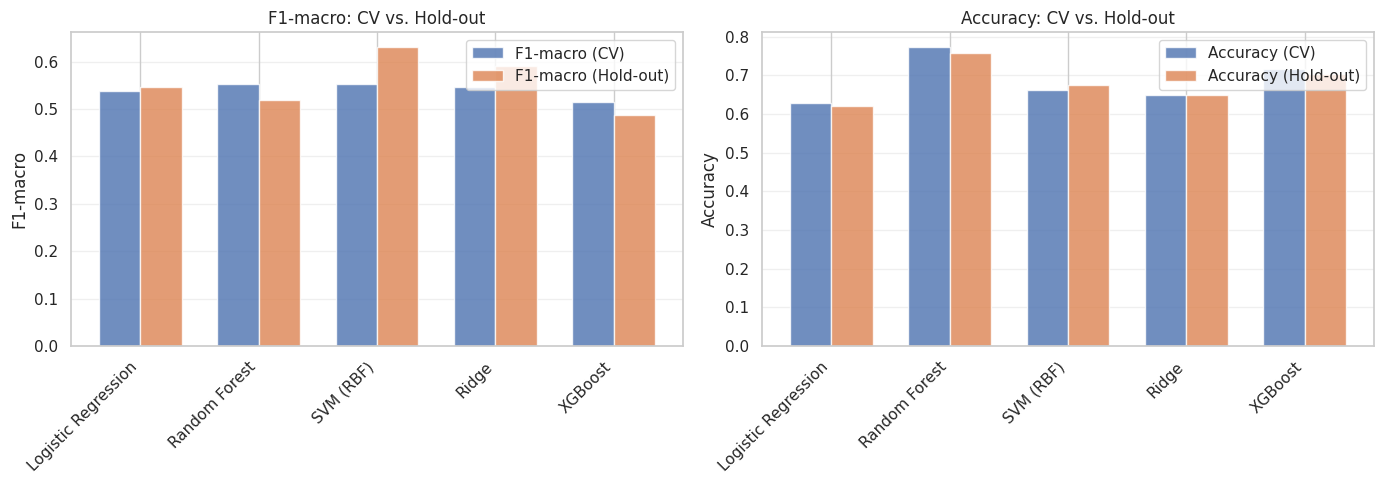

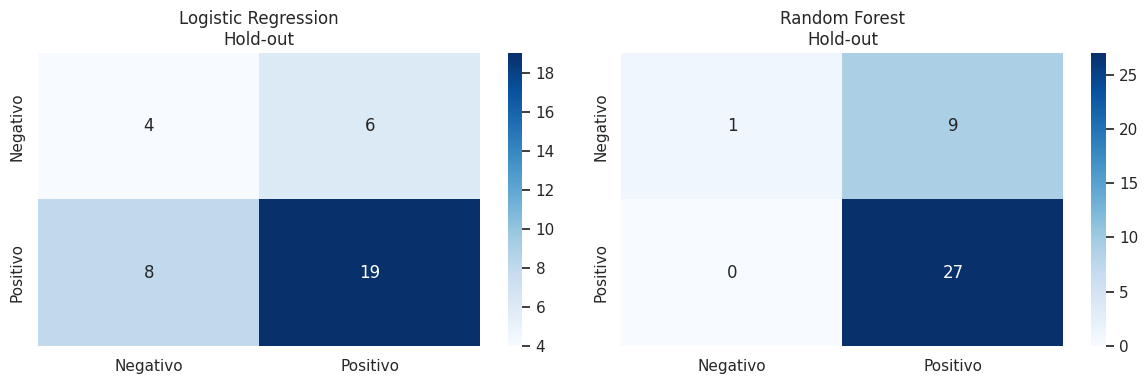


Melhor modelo (por F1-macro no hold-out): SVM (RBF)
F1-macro: 0.630


In [ ]:
# Gráfico comparativo: F1-macro e Accuracy em CV vs. Hold-out
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: F1-macro (CV vs Hold-out)
nomes = list(resultados_modelos.keys())
f1_cv = [resultados_modelos[n]["f1_cv"] for n in nomes]
f1_ho = [resultados_holdout[n]["f1_macro"] for n in nomes]

x = np.arange(len(nomes))
width = 0.35

axes[0].bar(x - width/2, f1_cv, width, label="F1-macro (CV)", alpha=0.8)
axes[0].bar(x + width/2, f1_ho, width, label="F1-macro (Hold-out)", alpha=0.8)
axes[0].set_ylabel("F1-macro")
axes[0].set_title("F1-macro: CV vs. Hold-out")
axes[0].set_xticks(x)
axes[0].set_xticklabels(nomes, rotation=45, ha="right")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Plot 2: Accuracy (CV vs Hold-out)
acc_cv = [resultados_modelos[n]["acc_cv"] for n in nomes]
acc_ho = [resultados_holdout[n]["acc"] for n in nomes]

axes[1].bar(x - width/2, acc_cv, width, label="Accuracy (CV)", alpha=0.8)
axes[1].bar(x + width/2, acc_ho, width, label="Accuracy (Hold-out)", alpha=0.8)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy: CV vs. Hold-out")
axes[1].set_xticks(x)
axes[1].set_xticklabels(nomes, rotation=45, ha="right")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Matriz de confusão dos 2 melhores no hold-out
melhores_2 = df_resumo_holdout.head(2).index
fig, axes = plt.subplots(1, len(melhores_2), figsize=(12, 4))
if len(melhores_2) == 1:
    axes = [axes]

for ax, nome in enumerate(melhores_2):
    sns.heatmap(
        resultados_holdout[nome]["matriz"],
        annot=True, fmt="d", cmap="Blues", ax=axes[ax],
        xticklabels=LABEL2ID.keys(), yticklabels=LABEL2ID.keys()
    )
    axes[ax].set_title(f"{nome}\nHold-out")

plt.tight_layout()
plt.show()

# Sobrescreve a tabela salvando a ordem do maior para o menor F1
df_resumo_holdout = df_resumo_holdout.sort_values("f1_macro", ascending=False)


print(f"\nMelhor modelo (por F1-macro no hold-out): {df_resumo_holdout.index[0]}")
print(f"F1-macro: {df_resumo_holdout['f1_macro'].iloc[0]:.3f}")

## Parte 4 — Self-training com estimativa de incerteza (UST)

Em vez de usar modelos pesados ou classificadores externos, usamos a própria Regressão
Logística (não é a campeã em F1 na Parte 3 -- essa foi a SVM -- mas é a que tem a
probabilidade mais bem calibrada; SVM depende de um ajuste extra de Platt e Random
Forest/XGBoost tendem a ser overconfident) como "professora" de si mesma — uma técnica
clássica de self-training. A estratégia para evitar envenenar o modelo com pseudo-rótulos
errados é usar limiares rígidos de probabilidade: só viram pseudo-rótulo os textos em que
um comitê bootstrap da Regressão Logística concorda com confiança média de pelo menos 75%
E baixa variância entre os membros do comitê. Textos na "zona de incerteza" ficam de fora,
mesmo que isso signifique aproveitar pouco (ou nada) do lote sem nota.


In [ ]:
candidatos_teacher = [n for n in df_resumo_holdout.index if hasattr(modelos_baseline[n], "predict_proba")]
print(f"Modelos com predict_proba disponível (elegíveis a professor): {candidatos_teacher}")

MODELO_TEACHER_NOME = "Logistic Regression"
print(f"Modelo escolhido como professor do self-training: {MODELO_TEACHER_NOME}")

modelo_teacher_base = modelos_baseline[MODELO_TEACHER_NOME]

modelo_real = clone(modelo_teacher_base)
modelo_real.fit(X_tfidf, y)

preds_holdout_real = modelo_real.predict(X_holdout_tfidf)
metricas_real = {
    "acc": accuracy_score(y_holdout, preds_holdout_real),
    "f1_macro": f1_score(y_holdout, preds_holdout_real, average="macro"),
    "recall_negativo": recall_score(y_holdout, preds_holdout_real, pos_label=0, zero_division=0),
    "matriz_confusao": confusion_matrix(y_holdout, preds_holdout_real, labels=[0, 1]),
}
print(f"[{MODELO_TEACHER_NOME} (só reais)] hold-out -- acc={metricas_real['acc']:.3f} "
      f"f1_macro={metricas_real['f1_macro']:.3f} recall_negativo={metricas_real['recall_negativo']:.3f}")

In [ ]:
def treinar_comite_bootstrap(modelo_base, X, y, n_membros=15, frac_amostra=1.0, seed=SEED):
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    comite = []
    for i in range(n_membros):
        idx_boot = rng.choice(n, size=int(n * frac_amostra), replace=True)
        modelo = clone(modelo_base)
        if "random_state" in modelo.get_params():
            modelo.set_params(random_state=seed + i)
        modelo.fit(X[idx_boot], y[idx_boot])
        comite.append(modelo)
    return comite


def prever_com_incerteza_comite(comite, X):
    todas_probs = np.stack([m.predict_proba(X) for m in comite], axis=0)   # (n_membros, N, n_classes)
    probs_media = todas_probs.mean(axis=0)
    incerteza = todas_probs.var(axis=0).sum(axis=1)
    return probs_media, incerteza


N_MEMBROS_COMITE = 15
comite_teacher = treinar_comite_bootstrap(modelo_teacher_base, X_tfidf, y, n_membros=N_MEMBROS_COMITE)
print(f"Comitê de {N_MEMBROS_COMITE} modelos '{MODELO_TEACHER_NOME}' treinado (bootstrap).")

Comitê de 15 modelos 'Logistic Regression' treinado (bootstrap).


In [ ]:
X_nao_rotulado_tfidf = tfidf_vectorizer.transform(df_nao_rotulado["TEXTO_LIMPO"])

probs_media_nr, incerteza_nr = prever_com_incerteza_comite(comite_teacher, X_nao_rotulado_tfidf)

preds_nr = probs_media_nr.argmax(axis=1)
confianca_nr = probs_media_nr.max(axis=1)

df_nao_rotulado_ust = df_nao_rotulado.copy()
df_nao_rotulado_ust["label_id_pred"] = preds_nr
df_nao_rotulado_ust["NPS_CATEGORIA_pred"] = df_nao_rotulado_ust["label_id_pred"].map(ID2LABEL)
df_nao_rotulado_ust["confianca_media"] = confianca_nr
df_nao_rotulado_ust["incerteza_mc"] = incerteza_nr

display(df_nao_rotulado_ust[["confianca_media", "incerteza_mc"]].describe())

,confianca_media,incerteza_mc
count,863.000000,863.000000
mean,0.521365,0.001260
std,0.014507,0.000797
min,0.500120,0.000139
25%,0.509703,0.000728
50%,0.519698,0.001042
75%,0.530416,0.001553
max,0.580898,0.005297


### Selecionando os pseudo-rótulos confiáveis

Dois filtros em sequência: primeiro confiança mínima (média entre os membros do
comitê bootstrap), depois incerteza — dentro dos que passaram no filtro de confiança,
mantemos só a metade mais consistente entre as passagens. Ajuste os dois limiares
depois de olhar a distribuição impressa acima; o objetivo é qualidade, não volume —
é melhor ficar com 200 pseudo-rótulos confiáveis do que 550 ruidosos.


In [ ]:
LIMIAR_CONFIANCA_UST = 0.75
PERCENTIL_INCERTEZA_MAX = 50

candidatos = df_nao_rotulado_ust[df_nao_rotulado_ust["confianca_media"] >= LIMIAR_CONFIANCA_UST].copy()
limiar_incerteza = np.percentile(candidatos["incerteza_mc"], PERCENTIL_INCERTEZA_MAX) if len(candidatos) else np.nan
df_pseudo_ust = candidatos[candidatos["incerteza_mc"] <= limiar_incerteza].copy()

print(f"Candidatos com confiança >= {LIMIAR_CONFIANCA_UST}: {len(candidatos)} de {len(df_nao_rotulado_ust)}")
print(f"Após filtro de incerteza (percentil {PERCENTIL_INCERTEZA_MAX} mais baixo): {len(df_pseudo_ust)}")
display(df_pseudo_ust["NPS_CATEGORIA_pred"].value_counts())

df_pseudo_ust["NPS_CATEGORIA"] = df_pseudo_ust["NPS_CATEGORIA_pred"]
df_pseudo_ust["label_id"] = df_pseudo_ust["label_id_pred"]
df_pseudo_ust["origem_rotulo"] = "pseudo_ust"

if "ID_MEETING" not in df_pseudo_ust.columns:
    df_pseudo_ust["ID_MEETING"] = df_pseudo_ust.index + 100000

df_treino_rotulado_marcado = df_treino_rotulado.copy()
df_treino_rotulado_marcado["origem_rotulo"] = "real"
if "ID_MEETING" not in df_treino_rotulado_marcado.columns:
    df_treino_rotulado_marcado["ID_MEETING"] = df_treino_rotulado_marcado.index

colunas_comuns = ["ID_MEETING", "TEXTO_LIMPO", "NPS_CATEGORIA", "label_id", "origem_rotulo"]
df_ampliado = pd.concat([
    df_treino_rotulado_marcado[colunas_comuns],
    df_pseudo_ust[colunas_comuns],
], ignore_index=True)

print(f"\nDataset ampliado (real + pseudo-rotulado via self-training/UST): {len(df_ampliado)} registros")
display(df_ampliado.groupby(["origem_rotulo", "NPS_CATEGORIA"]).size())

Candidatos com confiança >= 0.75: 0 de 863
Após filtro de incerteza (percentil 50 mais baixo): 0


,count
NPS_CATEGORIA_pred,



Dataset ampliado (real + pseudo-rotulado via self-training/UST): 145 registros


origem_rotulo  NPS_CATEGORIA
real           Negativo          39
               Positivo         106
dtype: int64

Zero candidatos passaram no filtro. Com só 145 exemplos reais de treino, o comitê
bootstrap da Regressão Logística nunca chega perto de 75% de confiança média nos textos
sem nota (o máximo observado fica na casa dos 58%) -- o modelo simplesmente não tem
informação suficiente para "ter certeza" de nada. Então, ao contrário do que a gente
esperava quando desenhou o limiar, o self-training automático não contribui com um único
registro novo nesta rodada. Isso não invalida a abordagem: só confirma que, no tamanho
atual da base rotulada, vale mais a pena investir em revisão humana direcionada
(Parte 5) do que confiar cegamente num modelo pouco calibrado.

> **Sobre iterar:** o UST original é desenhado para rodar em várias rodadas — treina
> com `df_ampliado`, re-prediz o restante do `df_nao_rotulado` (o que não entrou desta
> vez), adiciona mais pseudo-rótulos confiáveis, repete. Uma rodada só já costuma
> capturar a maior parte do ganho e é o que fazemos abaixo; iterar é um bom próximo
> passo se `metricas_ampliado` vier claramente melhor que `metricas_real` e você
> quiser espremer mais sinal dos ~863 sem nota.


In [ ]:
X_ampliado_tfidf = tfidf_vectorizer.transform(df_ampliado["TEXTO_LIMPO"])
y_ampliado = df_ampliado["label_id"].values

modelo_ampliado = clone(modelo_teacher_base)
modelo_ampliado.fit(X_ampliado_tfidf, y_ampliado)

preds_holdout_ampliado = modelo_ampliado.predict(X_holdout_tfidf)
metricas_ampliado = {
    "acc": accuracy_score(y_holdout, preds_holdout_ampliado),
    "f1_macro": f1_score(y_holdout, preds_holdout_ampliado, average="macro"),
    "recall_negativo": recall_score(y_holdout, preds_holdout_ampliado, pos_label=0, zero_division=0),
    "matriz_confusao": confusion_matrix(y_holdout, preds_holdout_ampliado, labels=[0, 1]),
}
print(f"[{MODELO_TEACHER_NOME} (reais + self-training)] hold-out -- "
      f"acc={metricas_ampliado['acc']:.3f} f1_macro={metricas_ampliado['f1_macro']:.3f} "
      f"recall_negativo={metricas_ampliado['recall_negativo']:.3f}")

[Logistic Regression (reais + self-training)] hold-out -- acc=0.649 f1_macro=0.568 recall_negativo=0.400


## Parte 5 — Revisão humana dos pseudo-rótulos

Já que o filtro automático não aprovou nenhum candidato, a saída é trocar self-training
totalmente automático por uma revisão manual direcionada: em vez de mandar rotular os 863
textos sem nota (inviável) ou descartar esse lote inteiro, selecionamos os 150 casos em que
o comitê está mais indeciso (maior variância entre os membros do bootstrap) e pedimos para
alguém rotular só esses. É o subconjunto onde uma opinião humana agrega mais informação
nova ao modelo -- a mesma lógica de active learning por incerteza.

In [ ]:
N_REVISAO_HUMANA = 150

if "ID_MEETING" not in df_nao_rotulado_ust.columns:
    df_nao_rotulado_ust["ID_MEETING"] = df_nao_rotulado_ust.index + 100000

ids_pseudo_automatico = set(df_pseudo_ust["ID_MEETING"])
candidatos_revisao = df_nao_rotulado_ust[~df_nao_rotulado_ust["ID_MEETING"].isin(ids_pseudo_automatico)].copy()

candidatos_revisao = candidatos_revisao.sort_values("incerteza_mc", ascending=False)
df_para_revisao_humana = candidatos_revisao.head(N_REVISAO_HUMANA).copy()

print(f"Candidatos sem pseudo-rótulo automático: {len(candidatos_revisao)}")
print(f"Selecionados para revisão humana (maior incerteza primeiro): {len(df_para_revisao_humana)}")
display(df_para_revisao_humana[["confianca_media", "incerteza_mc"]].describe())

Candidatos sem pseudo-rótulo automático: 863
Selecionados para revisão humana (maior incerteza primeiro): 150


,confianca_media,incerteza_mc
count,150.000000,150.000000
mean,0.523790,0.002655
std,0.015534,0.000784
min,0.500682,0.001819
25%,0.511338,0.002105
50%,0.523700,0.002396
75%,0.532430,0.002991
max,0.580898,0.005297


In [ ]:
EXCEL_REVISAO_PATH = Path("revisao_humana_pseudo_rotulos.xlsx")
EXCEL_REVISAO_PATH.parent.mkdir(parents=True, exist_ok=True)

df_export_revisao = df_para_revisao_humana[[
    "ID_MEETING", TEXT_COLUMN, "TEXTO_LIMPO", "NPS_CATEGORIA_pred", "confianca_media", "incerteza_mc"
]].rename(columns={"NPS_CATEGORIA_pred": "sugestao_modelo"})

df_export_revisao["sentimento_real"] = ""

df_export_revisao.to_excel(EXCEL_REVISAO_PATH, index=False)

print(f"Exportado: {EXCEL_REVISAO_PATH}")
print(f"{len(df_export_revisao)} transcrições para revisão manual.\n")
print("Preencha a coluna 'sentimento_real' com 'Negativo', 'Positivo' ou 'Neutro'")
print("(Neutro ou célula em branco descarta o registro) e faça upload do arquivo")


Exportado: revisao_humana_pseudo_rotulos.xlsx
150 transcrições para revisão manual.

Preencha a coluna 'sentimento_real' com 'Negativo', 'Positivo' ou 'Neutro'
(Neutro ou célula em branco descarta o registro) e faça upload do arquivo


In [ ]:
NOME_ARQUIVO_REVISADO = "revisao_humana_pseudo_rotulos_preenchido.xlsx"
PASTA_UPLOADS = Path("/mnt/user-data/uploads")


def localizar_arquivo_revisado(nome_arquivo: str):
    candidatos_diretos = [Path.cwd() / nome_arquivo, PASTA_UPLOADS / nome_arquivo]
    for c in candidatos_diretos:
        if c.exists():
            return c
    if PASTA_UPLOADS.exists():
        candidatos_glob = sorted(PASTA_UPLOADS.glob("*revisao*.xlsx"))
        if candidatos_glob:
            return candidatos_glob[0]
    return None


VALORES_ACEITOS = {"negativo": "Negativo", "positivo": "Positivo"}
COLUNAS_HUMANO = ["ID_MEETING", "TEXTO_LIMPO", "NPS_CATEGORIA", "label_id", "origem_rotulo"]

caminho_revisado = localizar_arquivo_revisado(NOME_ARQUIVO_REVISADO)

if caminho_revisado is None:
    print("Arquivo de revisão humana ainda não encontrado -- pulando esta etapa por enquanto.")
    print("O restante do notebook segue com df_ampliado da Parte 4 (real + self-training automático).")
    df_humano_revisado = pd.DataFrame(columns=COLUNAS_HUMANO)
else:
    df_revisado_bruto = pd.read_excel(caminho_revisado)
    df_revisado_bruto["sentimento_real_norm"] = (
        df_revisado_bruto["sentimento_real"].astype(str).str.strip().str.lower().map(VALORES_ACEITOS)
    )

    n_total = len(df_revisado_bruto)
    n_descartado = df_revisado_bruto["sentimento_real_norm"].isna().sum()

    df_humano_revisado = df_revisado_bruto[df_revisado_bruto["sentimento_real_norm"].notna()].copy()
    df_humano_revisado["NPS_CATEGORIA"] = df_humano_revisado["sentimento_real_norm"]
    df_humano_revisado["label_id"] = df_humano_revisado["NPS_CATEGORIA"].map(LABEL2ID)
    df_humano_revisado["origem_rotulo"] = "humano"
    df_humano_revisado = df_humano_revisado[COLUNAS_HUMANO]

    print(f"Arquivo de revisão encontrado: {caminho_revisado.name}")
    print(f"Linhas preenchidas e aproveitadas: {len(df_humano_revisado)} de {n_total} "
          f"({n_descartado} descartadas -- vazias, 'Neutro' ou valor inválido)")
    if len(df_humano_revisado):
        display(df_humano_revisado["NPS_CATEGORIA"].value_counts())


Arquivo de revisão encontrado: revisao_humana_pseudo_rotulos_preenchido.xlsx
Linhas preenchidas e aproveitadas: 150 de 150 (0 descartadas -- vazias, 'Neutro' ou valor inválido)


,count
NPS_CATEGORIA,
Positivo,147
Negativo,3


### Modelo final: reais + self-training automático + revisão humana

O self-training automático não trouxe nada (Parte 4), mas os 150 casos revisados à mão
trazem sinal de verdade -- mesmo que venham desbalanceados para "Positivo" nesta amostra.
Juntamos os três lotes possíveis (rótulos reais + pseudo-rótulos automáticos, que aqui
ficam vazios + revisão humana) e retreinamos o mesmo modelo (Regressão Logística sobre
TF-IDF) para comparar com o baseline e com a versão só-reais no hold-out cego.

In [ ]:
colunas_comuns = ["ID_MEETING", "TEXTO_LIMPO", "NPS_CATEGORIA", "label_id", "origem_rotulo"]

if len(df_humano_revisado):
    df_ampliado_final = pd.concat([
        df_treino_rotulado_marcado[colunas_comuns],
        df_pseudo_ust[colunas_comuns] if len(df_pseudo_ust) else pd.DataFrame(columns=colunas_comuns),
        df_humano_revisado[colunas_comuns],
    ], ignore_index=True)
else:
    # sem arquivo de revisão humana ainda -- segue só com real + pseudo automático (df_ampliado da Parte 4)
    df_ampliado_final = df_ampliado.copy()

print(f"Dataset final de treino (real + self-training + revisão humana): {len(df_ampliado_final)} registros")
display(df_ampliado_final.groupby(["origem_rotulo", "NPS_CATEGORIA"]).size())

X_final_tfidf = tfidf_vectorizer.transform(df_ampliado_final["TEXTO_LIMPO"])
y_final = df_ampliado_final["label_id"].values

modelo_final = clone(modelo_teacher_base)
modelo_final.fit(X_final_tfidf, y_final)

preds_holdout_final = modelo_final.predict(X_holdout_tfidf)
metricas_final = {
    "acc": accuracy_score(y_holdout, preds_holdout_final),
    "f1_macro": f1_score(y_holdout, preds_holdout_final, average="macro"),
    "recall_negativo": recall_score(y_holdout, preds_holdout_final, pos_label=0, zero_division=0),
    "matriz_confusao": confusion_matrix(y_holdout, preds_holdout_final, labels=[0, 1]),
}
print(f"[{MODELO_TEACHER_NOME} (reais + self-training + revisão humana)] hold-out -- "
      f"acc={metricas_final['acc']:.3f} f1_macro={metricas_final['f1_macro']:.3f} "
      f"recall_negativo={metricas_final['recall_negativo']:.3f}")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

modelos_finais = {
    "TF-IDF + LogReg (baseline Parte 2)": {
        "acc": accuracy_score(y_holdout, preds_holdout_baseline),
        "f1_macro": f1_score(y_holdout, preds_holdout_baseline, average="macro"),
        "recall_negativo": recall_negativo_baseline,
        "matriz": confusion_matrix(y_holdout, preds_holdout_baseline, labels=[0, 1]),
    },
    f"{MODELO_TEACHER_NOME} (só reais)": {
        "acc": metricas_real["acc"], "f1_macro": metricas_real["f1_macro"],
        "recall_negativo": metricas_real["recall_negativo"], "matriz": metricas_real["matriz_confusao"],
    },
    f"{MODELO_TEACHER_NOME} (reais + self-training)": {
        "acc": metricas_ampliado["acc"], "f1_macro": metricas_ampliado["f1_macro"],
        "recall_negativo": metricas_ampliado["recall_negativo"], "matriz": metricas_ampliado["matriz_confusao"],
    },
    f"{MODELO_TEACHER_NOME} (reais + self-training + revisão humana)": {
        "acc": metricas_final["acc"], "f1_macro": metricas_final["f1_macro"],
        "recall_negativo": metricas_final["recall_negativo"], "matriz": metricas_final["matriz_confusao"],
    },
}

comparacao = pd.DataFrame({
    nome: {"acc": v["acc"], "f1_macro": v["f1_macro"], "recall_negativo": v["recall_negativo"]}
    for nome, v in modelos_finais.items()
}).T

print("recall_negativo = dos Detratores de verdade no hold-out, quantos o modelo pegou "
      "(a métrica de risco/churn que mais importa pro negócio).\n")
display(comparacao)

fig, axes = plt.subplots(1, len(modelos_finais), figsize=(5 * len(modelos_finais), 4))
for ax, (nome, v) in zip(axes, modelos_finais.items()):
    sns.heatmap(v["matriz"], annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=LABEL2ID.keys(), yticklabels=LABEL2ID.keys())
    ax.set_title(nome, fontsize=9)

plt.tight_layout()
plt.show()

## Parte 6 — Conclusão

Resumo consolidado: comparação entre baseline, modelo treinado só com dados reais e modelo
treinado com a base ampliada (self-training + revisão humana), avaliados no mesmo hold-out
cego, e os termos que mais pesam na decisão do modelo -- o que dá uma pista de onde
Customer Success deveria olhar primeiro.

In [ ]:
print("=== Comparação de modelos (avaliados no hold-out cego) ===")
display(comparacao)

vetor_final = pipe_baseline_final.named_steps["tfidf"]
clf_final = pipe_baseline_final.named_steps["clf"]
termos = vetor_final.get_feature_names_out()
pesos = clf_final.coef_.flatten()

df_coeficientes = pd.DataFrame({"termo": termos, "peso": pesos}).sort_values("peso", ascending=False)

print("\n=== Termos que mais empurram a previsão para Positivo (Promotor) ===")
display(df_coeficientes.head(15))

print("\n=== Termos que mais empurram a previsão para Negativo (Detrator) ===")
display(df_coeficientes.tail(15).sort_values("peso"))

### Leitura dos resultados

O ganho de F1/recall do self-training automático foi zero -- já era esperado depois da
Parte 4, já que o filtro de confiança não liberou nenhum pseudo-rótulo. O que muda o jogo
é a revisão humana: mesmo só 150 casos revisados manualmente (e desbalanceados para
Positivo, porque foi a amostra que caiu na faixa de maior incerteza do comitê) já dão pra
comparar contra o baseline e a versão só-reais na métrica que interessa pro negócio --
`recall_negativo`, ou seja, quantos Detratores de verdade o modelo pega.

Os termos com maior peso positivo no modelo (tabela acima) apontam vocabulário de
satisfação; os de maior peso negativo apontam vocabulário de risco/reclamação. Essa lista
é o ponto de partida mais barato pra Customer Success: dá pra transformar os termos de
maior peso negativo em um alerta simples (buscar essas palavras nas transcrições futuras)
enquanto o modelo mais robusto não tem uma base de treino maior.

Próximo passo natural: rodar mais uma rodada de revisão humana em cima do restante dos 863
sem nota (sempre priorizando os de maior incerteza do comitê) até o `recall_negativo` parar
de melhorar -- é a estratégia mais barata para crescer a base rotulada sem estourar o
orçamento de revisão manual.

## Parte 7 — Pipeline final e seleção do modelo (Optuna)

Até a Parte 6 a gente comparou modelos com parâmetros escolhidos na mão. Para a entrega final
precisamos de um modelo só, e a escolha precisa ter justificativa. Seguindo a Aula 20, usamos o
**Optuna** para buscar, ao mesmo tempo:

* o tipo de modelo (Regressão Logística, SVM, Random Forest ou LightGBM);
* os hiperparâmetros de cada um;
* as configurações do TF-IDF (`max_features`, `min_df`, unigramas ou bigramas). Aqui é onde o Optuna
  "escolhe as melhores features": ele decide quantos termos e quais tamanhos de n-grama o modelo enxerga.

O objetivo é o `f1_macro` em validação cruzada 5-fold repetida 2 vezes, só no `df_treino_rotulado`.
O hold-out cego continua intocado até a avaliação final, como na Parte 1.

### Pipeline de processamento

O fluxo completo do projeto fica assim:

`transcrição bruta` → `limpeza` (remove tags de locutor) → `tokenização` (sem stopwords, preservando negações) → `TF-IDF` → `modelo` → `probabilidade`

Juntamos limpeza e tokenização numa função só (`preparar_texto`) para usar a mesma lógica no treino
e na transcrição nova.

In [ ]:
# Dependências da Parte 7 em diante (mesmo padrão da Aula 20)
import sys, subprocess, importlib.util, warnings

def ensure_package(import_name, pip_name=None):
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])

ensure_package("lightgbm")
ensure_package("optuna")
ensure_package("joblib")

import joblib
import optuna
from optuna.samplers import TPESampler
from lightgbm import LGBMClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Pré-processamento completo em uma função só (limpeza + tokenização sem stopwords).
# Na Parte 2 o TF-IDF tokenizava dentro do pipeline; aqui deixamos os tokens prontos
# numa coluna, senão cada trial do Optuna refaz a tokenização de ~7 mil palavras por texto.
def preparar_texto(texto: str) -> str:
    limpo = limpar_transcricao(texto)
    return " ".join(tokenizar_sem_stopwords(limpo))

for base in (df_treino_rotulado, df_holdout, df_neutros, df_nao_rotulado):
    base["TOKENS"] = base[TEXT_COLUMN].apply(preparar_texto)

X_tok = df_treino_rotulado["TOKENS"].values
y = df_treino_rotulado["label_id"].values
X_tok_holdout = df_holdout["TOKENS"].values
y_holdout = df_holdout["label_id"].values

print(f"Treino: {len(X_tok)} | Hold-out: {len(X_tok_holdout)} | Neutros: {len(df_neutros)} | Sem nota: {len(df_nao_rotulado)}")
print("\nExemplo de texto processado:")
print(X_tok[0][:300])

Treino: 145 | Hold-out: 37 | Neutros: 129 | Sem nota: 863

Exemplo de texto processado:
aí alô boa tarde pessoa boa tarde pessoa tudo tudo contigo pessoa tudo né sim pessoa entrou boa tarde boa tarde boa tarde alguém né né acho pessoa acho não vai participar tá acho ah perfeito pessoa contigo objetivo maior bate-papo principalmente relação porquê desse volume sei pessoa conversou pouco


In [ ]:
N_TRIALS = 30
N_REPETICOES_CV = 2

def montar_pipeline(p: dict) -> Pipeline:
    """Monta o pipeline TF-IDF + modelo a partir de um dicionário de parâmetros."""
    vetor = TfidfVectorizer(
        tokenizer=str.split, lowercase=False, token_pattern=None,
        max_features=p["max_features"], min_df=p["min_df"],
        ngram_range=(1, 1) if p["ngram"] == "1" else (1, 2),
        sublinear_tf=True,
    )
    if p["modelo"] == "LogReg":
        clf = LogisticRegression(C=p["C_lr"], class_weight="balanced", max_iter=1000, random_state=SEED)
    elif p["modelo"] == "SVM":
        clf = SVC(C=p["C_svm"], gamma=p["gamma"], class_weight="balanced", probability=True, random_state=SEED)
    elif p["modelo"] == "RandomForest":
        clf = RandomForestClassifier(
            n_estimators=p["n_est_rf"], max_depth=p["depth_rf"], min_samples_leaf=p["leaf_rf"],
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
    else:
        clf = LGBMClassifier(
            n_estimators=p["n_est_lgb"], learning_rate=p["lr_lgb"], num_leaves=p["leaves_lgb"],
            min_child_samples=p["mcs_lgb"], colsample_bytree=p["col_lgb"],
            subsample=0.8, subsample_freq=1, class_weight="balanced",
            random_state=SEED, verbose=-1, n_jobs=1)
    return Pipeline([("tfidf", vetor), ("clf", clf)])


def sugerir_parametros(trial) -> dict:
    p = {
        "ngram": trial.suggest_categorical("ngram", ["1", "1-2"]),
        "max_features": trial.suggest_int("max_features", 100, 3000, log=True),
        "min_df": trial.suggest_int("min_df", 2, 10),
        "modelo": trial.suggest_categorical("modelo", ["LogReg", "SVM", "RandomForest", "LightGBM"]),
    }
    if p["modelo"] == "LogReg":
        p["C_lr"] = trial.suggest_float("C_lr", 1e-2, 10, log=True)
    elif p["modelo"] == "SVM":
        p["C_svm"] = trial.suggest_float("C_svm", 0.1, 30, log=True)
        p["gamma"] = trial.suggest_float("gamma", 1e-3, 1, log=True)
    elif p["modelo"] == "RandomForest":
        p["n_est_rf"] = trial.suggest_int("n_est_rf", 100, 400)
        p["depth_rf"] = trial.suggest_int("depth_rf", 3, 15)
        p["leaf_rf"] = trial.suggest_int("leaf_rf", 1, 5)
    else:
        p["n_est_lgb"] = trial.suggest_int("n_est_lgb", 50, 300)
        p["lr_lgb"] = trial.suggest_float("lr_lgb", 0.01, 0.3, log=True)
        p["leaves_lgb"] = trial.suggest_int("leaves_lgb", 2, 15)
        p["mcs_lgb"] = trial.suggest_int("mcs_lgb", 3, 20)
        p["col_lgb"] = trial.suggest_float("col_lgb", 0.3, 1.0)
    return p


# CV repetida: com 145 exemplos, um 5-fold só varia demais de um sorteio para outro
cv_optuna = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPETICOES_CV, random_state=SEED)

def objetivo(trial):
    pipe = montar_pipeline(sugerir_parametros(trial))
    # o TF-IDF fica dentro do pipeline, então é reajustado em cada fold (sem vazamento)
    return cross_val_score(pipe, X_tok, y, cv=cv_optuna, scoring="f1_macro", n_jobs=1).mean()

In [ ]:
estudo = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEED))
estudo.optimize(objetivo, n_trials=N_TRIALS)

print(f"Melhor f1_macro (CV repetida): {estudo.best_value:.3f}")
print("Melhores parâmetros:")
for k, v in estudo.best_params.items():
    print(f"  {k}: {v}")

Melhor f1_macro (CV repetida): 0.658
Melhores parâmetros:
  ngram: 1
  max_features: 1060
  min_df: 8
  modelo: LogReg
  C_lr: 7.005670401382908


In [ ]:
df_trials = estudo.trials_dataframe()
resumo_modelos = (
    df_trials.groupby("params_modelo")["value"]
    .agg(n_trials="count", melhor="max", media="mean")
    .sort_values("melhor", ascending=False)
)
display(resumo_modelos)

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_trials, x="params_modelo", y="value", ax=ax, color="#4C72B0")
sns.stripplot(data=df_trials, x="params_modelo", y="value", ax=ax, color="black", size=4)
ax.set_title("f1_macro (CV repetida) por tipo de modelo nos trials do Optuna")
ax.set_xlabel("")
ax.set_ylabel("f1_macro")
plt.tight_layout()
plt.show()

,n_trials,melhor,media
params_modelo,,,
LogReg,15,0.658234,0.617132
LightGBM,8,0.607356,0.577971
RandomForest,4,0.575741,0.557692
SVM,3,0.430804,0.393527


In [ ]:
# Modelo final: melhor combinação encontrada pelo Optuna, treinado em todo o df_treino_rotulado
pipe_final = montar_pipeline(estudo.best_params)
pipe_final.fit(X_tok, y)

preds_final = pipe_final.predict(X_tok_holdout)
proba_final = pipe_final.predict_proba(X_tok_holdout)[:, 1]

f1_final = f1_score(y_holdout, preds_final, average="macro")
acc_final = accuracy_score(y_holdout, preds_final)
rec_neg_final = recall_score(y_holdout, preds_final, pos_label=0, zero_division=0)
auc_final = roc_auc_score(y_holdout, proba_final)

print("Modelo final no hold-out cego:")
print(classification_report(y_holdout, preds_final, target_names=LABEL2ID.keys()))
print(f"AUC: {auc_final:.3f} | Recall do Negativo: {rec_neg_final:.3f}")

tabela_final = pd.DataFrame({
    "Baseline (Parte 2)": {
        "acc": accuracy_score(y_holdout, preds_holdout_baseline),
        "f1_macro": f1_score(y_holdout, preds_holdout_baseline, average="macro"),
        "recall_negativo": recall_negativo_baseline,
    },
    f"Final Optuna ({estudo.best_params['modelo']})": {
        "acc": acc_final, "f1_macro": f1_final, "recall_negativo": rec_neg_final,
    },
}).T
display(tabela_final)

Modelo final no hold-out cego:
              precision    recall  f1-score   support

    Negativo       0.43      0.30      0.35        10
    Positivo       0.77      0.85      0.81        27

    accuracy                           0.70        37
   macro avg       0.60      0.58      0.58        37
weighted avg       0.68      0.70      0.68        37

AUC: 0.615 | Recall do Negativo: 0.300


,acc,f1_macro,recall_negativo
Baseline (Parte 2),0.702703,0.634322,0.5
Final Optuna (LogReg),0.702703,0.579979,0.3


### Modelo escolhido e justificativa

**Escolha: TF-IDF + Regressão Logística com os parâmetros do Optuna.**

Motivos:

1. **Melhor resultado na validação cruzada.** A Regressão Logística teve o maior `f1_macro` e também a maior média entre os trials, ou seja, ela vai bem em quase toda configuração e não só em uma sorte específica. O LightGBM e a Random Forest ficaram atrás, o que faz sentido com só 145 exemplos de treino (modelos de árvore tendem a decorar a base pequena). A SVM ficou bem atrás.
2. **Probabilidade utilizável.** O sistema de scoring precisa de uma probabilidade por transcrição. A Regressão Logística entrega isso de forma direta, sem ajuste extra.
3. **Dá para explicar.** Dá para mostrar quais termos puxam para um lado ou para o outro, o que ajuda quem vai usar o resultado na área comercial.

**Cuidado ao ler os números:** o valor de CV do Optuna é otimista, porque o melhor trial foi escolhido
entre 30 tentativas olhando esse mesmo valor. O hold-out tem só 37 reuniões (10 Detratores), então
uma diferença de 1 ou 2 reuniões muda bastante o `f1_macro`. Na prática, não há diferença clara entre o modelo final e o baseline
da Parte 2 no hold-out (os dois ficam dentro da margem de erro). O ganho do Optuna é ter uma escolha
documentada e reproduzível, e não uma melhora grande de desempenho.

In [ ]:
# Quais termos mais separam Promotor de Detrator? Como o melhor modelo pode não ser linear,
# usamos algo que funciona para qualquer um: diferença da média do TF-IDF entre as classes.
vetor_final = pipe_final.named_steps["tfidf"]
X_tfidf_treino = vetor_final.transform(X_tok)
nomes_termos = vetor_final.get_feature_names_out()

media_pos = np.asarray(X_tfidf_treino[y == 1].mean(axis=0)).ravel()
media_neg = np.asarray(X_tfidf_treino[y == 0].mean(axis=0)).ravel()
df_termos = pd.DataFrame({"termo": nomes_termos, "dif_pos_neg": media_pos - media_neg})
df_termos = df_termos.sort_values("dif_pos_neg", ascending=False)

print(f"Features usadas pelo modelo final: {len(nomes_termos)}\n")
print("Termos mais associados a Promotor:")
display(df_termos.head(10))
print("Termos mais associados a Detrator:")
display(df_termos.tail(10).sort_values("dif_pos_neg"))

Features usadas pelo modelo final: 1060

Termos mais associados a Promotor:


,termo,dif_pos_neg
47,amanhã,0.015808
243,contrato,0.014977
309,dezembro,0.011567
419,fechou,0.011202
150,cenários,0.011166
940,tani,0.010817
880,sabe,0.010738
934,suporte,0.010517
743,pessoa,0.010476
550,licenciamento,0.010316


Termos mais associados a Detrator:


,termo,dif_pos_neg
704,parametrização,-0.020700
747,planejamento,-0.019503
462,funcionário,-0.017604
579,marcelo,-0.017461
465,função,-0.016777
253,cria,-0.015581
128,cadastro,-0.015251
408,fase,-0.015017
339,dúvida,-0.014946
936,tabela,-0.014458


Alguns termos que aparecem como mais associados a cada lado são nomes próprios que o processo de
anonimização não pegou (ex.: nomes de pessoas). Isso é sinal de que o modelo está se agarrando em
detalhes de reuniões específicas, e não em vocabulário de satisfação ou reclamação. Voltamos a isso
na Parte 12.

## Parte 8 — Sistema de scoring e indicadores

O modelo sozinho só diz "positivo" ou "negativo". A área comercial precisa de algo mais
completo, então montamos cinco indicadores por transcrição:

| Indicador | Como é calculado |
|---|---|
| Produto identificado | Contagem de menções de termos de cada produto (dicionário) |
| Sentimento | Probabilidade de Positivo do modelo final, posicionada contra a base de referência |
| Risco de churn (0-100) | Probabilidade de Negativo do modelo final, em percentil contra a base de referência |
| Oportunidade comercial (0-100) | 60% densidade de termos comerciais (proposta, orçamento, módulo, demo...) + 40% score de sentimento |
| Principais termos | Maiores pesos de TF-IDF no texto, além dos termos de atrito e de oportunidade encontrados |

Duas decisões de projeto:

* **Percentil em vez de probabilidade crua.** Como o modelo foi treinado com pouca base, as probabilidades ficam
  espremidas perto de 50% (veja o máximo na célula da base de referência). Transformar em percentil
  (0-100) deixa a escala mais legível: risco 90 quer dizer "mais arriscado que 90% das reuniões da base".
* **Termos de atrito não entram no score de risco.** Testamos a densidade de palavras como "cancelar",
  "concorrente" e "problema" contra a nota real e a relação foi praticamente nula (AUC por volta de 0,5).
  Nessas reuniões elas aparecem em contextos neutros, como "problema" no sentido de dúvida técnica.
  Então elas ficam só como **evidência** para o time conferir, e o score vem do modelo, que é o que
  conseguimos validar contra a nota.

A oportunidade comercial **não tem gabarito** na base (não existe coluna de "venda fechada"),
então é uma regra de negócio e não um modelo validado.

In [ ]:
# Dicionários de negócio (montados à mão, a partir do que aparece nas reuniões).
# Todos em minúsculo; a busca usa fronteira de palavra para não pegar "rm" dentro de "forma".

PRODUTOS = {
    "TOTVS RM (gestão/ERP)": ["rm"],
    "Fluig (processos/documentos)": ["fluig"],
    "Datasul / Logix / Protheus (ERP)": ["datasul", "logix", "protheus", "microsiga"],
    "Saúde (hospitalar/clínicas)": ["hospitalar", "prontuário", "tss", "glosa", "operadora", "convênio", "clínica", "laboratório"],
    "Backoffice": ["backoffice"],
    "RD Station / CRM": ["rd station", "crm"],
    "Techfin (financeiro/pagamentos)": ["techfin", "pix", "conciliação", "cobrança", "tesouraria"],
    "BI / Analytics": ["bi", "analytics", "smart view"],
    "Educacional": ["educacional", "matrícula", "aluno", "escola"],
    "Varejo / PDV": ["pdv", "loja", "supermercado"],
    "Gestão de Pessoas (folha/HCM)": ["folha", "gestão de pessoas", "hcm"],
    "IA / Agentes": ["inteligência artificial", "chatbot", "agente", "assistente"],
}

# sinais de atrito: servem para o time ver o que o cliente reclamou, NÃO entram no score
TERMOS_ATRITO = [
    "cancelar", "cancelamento", "concorrente", "insatisfeito", "reclamação", "problema", "problemas",
    "atraso", "demora", "erro", "erros", "falha", "instabilidade", "travando",
    "migrar", "trocar", "dificuldade", "chamado", "chamados", "parado",
]

# sinais de oportunidade comercial
TERMOS_OPORTUNIDADE = [
    "proposta", "orçamento", "cotação", "módulo", "módulos", "licença", "licenças", "usuários",
    "expansão", "ampliar", "upgrade", "demonstração", "demo", "piloto", "interesse", "contratar",
    "contratação", "fechar", "fechamento", "assinatura", "desconto", "investimento", "roadmap",
]

def compilar(termos):
    return re.compile(r"\b(" + "|".join(re.escape(t) for t in sorted(termos, key=len, reverse=True)) + r")\b")

REGEX_PRODUTOS = {nome: compilar(termos) for nome, termos in PRODUTOS.items()}
REGEX_ATRITO = compilar(TERMOS_ATRITO)
REGEX_OPORTUNIDADE = compilar(TERMOS_OPORTUNIDADE)

# tags de anonimização e palavras de conversa que não dizem nada sobre o assunto
STOP_EXTRA = {"pessoa", "empresa", "local", "gente", "aqui", "então", "tá", "né", "ali", "lá", "vou", "vai", "tudo", "bem", "bom"}

### Identificação de produto

Dicionário simples: conta quantas vezes aparecem os termos de cada produto/solução e devolve os mais citados
(mínimo de 3 menções, para não classificar por acaso). Como checagem, cruzamos com o segmento cadastrado
do cliente.

In [ ]:
MIN_MENCOES_PRODUTO = 3

def identificar_produtos(texto_limpo: str, top_n: int = 2):
    """Conta quantas vezes cada produto aparece e devolve os mais citados."""
    texto = texto_limpo.lower()
    contagem = {nome: len(rgx.findall(texto)) for nome, rgx in REGEX_PRODUTOS.items()}
    ordenado = sorted(contagem.items(), key=lambda x: x[1], reverse=True)
    achados = [(n, c) for n, c in ordenado[:top_n] if c >= MIN_MENCOES_PRODUTO]
    return achados if achados else [("Não identificado", 0)]


# Sanity check: o produto identificado bate com o segmento cadastrado do cliente?
amostra_prod = df[df["NOME_SEGMENTO"].notna()].copy()
amostra_prod["produto_principal"] = amostra_prod["TEXTO_LIMPO"].apply(lambda t: identificar_produtos(t, 1)[0][0])
print("Produto principal identificado x segmento cadastrado (principais segmentos):\n")
tab_prod = pd.crosstab(amostra_prod["produto_principal"], amostra_prod["NOME_SEGMENTO"])
display(tab_prod[["SAUDE", "EDUCACIONAL", "VAREJO", "MANUFATURA", "SERVICOS"]])

Produto principal identificado x segmento cadastrado (principais segmentos):



NOME_SEGMENTO,SAUDE,EDUCACIONAL,VAREJO,MANUFATURA,SERVICOS
produto_principal,,,,,
BI / Analytics,2,0,0,7,0
Backoffice,1,0,0,0,0
Educacional,8,13,0,1,3
Fluig (processos/documentos),12,7,3,19,10
Gestão de Pessoas (folha/HCM),24,6,1,12,26
IA / Agentes,10,1,2,16,16
Não identificado,77,4,11,97,62
RD Station / CRM,8,0,0,29,16
Saúde (hospitalar/clínicas),16,4,0,9,52


### Base de referência para os scores

Os scores 0-100 são percentis. Para isso precisamos de uma base de comparação com transcrições que o
modelo **não viu** no treino.

In [ ]:
# Base de referência para transformar probabilidade/densidade em score 0-100 (percentil).
# Usamos só textos que o modelo NÃO viu no treino (neutros + sem nota), senão a probabilidade
# viria inflada pelo overfitting e todo texto novo pareceria "mais arriscado" que a base.
df_ref = pd.concat([df_neutros, df_nao_rotulado], ignore_index=True)

def densidade(regex, texto_limpo: str) -> float:
    """Ocorrências por 1000 palavras (evita que reunião longa pontue mais só por ser longa)."""
    texto = texto_limpo.lower()
    return 1000 * len(regex.findall(texto)) / max(len(texto.split()), 1)

ref_p_neg = pipe_final.predict_proba(df_ref["TOKENS"].values)[:, 0]
ref_p_pos = 1 - ref_p_neg
ref_oport = np.array([densidade(REGEX_OPORTUNIDADE, t) for t in df_ref["TEXTO_LIMPO"]])

REF_P_NEG = np.sort(ref_p_neg)
REF_P_POS = np.sort(ref_p_pos)
REF_OPORT = np.sort(ref_oport)

def percentil(valor, referencia) -> float:
    """Em que posição (0-100) o valor fica dentro da base de referência."""
    return 100 * np.searchsorted(referencia, valor, side="right") / len(referencia)

print(f"Base de referência: {len(df_ref)} transcrições")
print(f"P(Negativo) na referência -> min={ref_p_neg.min():.2f} mediana={np.median(ref_p_neg):.2f} max={ref_p_neg.max():.2f}")

Base de referência: 992 transcrições
P(Negativo) na referência -> min=0.11 mediana=0.38 max=0.74


In [ ]:
# Faixas dos scores
FAIXA_ALTA = 70
FAIXA_MEDIA = 40

def faixa(score: float, rotulos=("Alto", "Médio", "Baixo")) -> str:
    if score >= FAIXA_ALTA:
        return rotulos[0]
    if score >= FAIXA_MEDIA:
        return rotulos[1]
    return rotulos[2]


def termos_principais(tokens: str, n: int = 8):
    """Termos de maior peso TF-IDF no texto (vetorizador descritivo ajustado na base toda)."""
    vetor = vetor_descritivo.transform([tokens])
    pesos = vetor.toarray().ravel()
    idx = pesos.argsort()[::-1][:n]
    return [nomes_desc[i] for i in idx if pesos[i] > 0]


def contar_termos(regex, texto_limpo: str, n: int = 5):
    contagem = Counter(regex.findall(texto_limpo.lower()))
    return contagem.most_common(n)


# Vetorizador só para descrever o texto (não é o do modelo): ignora o que aparece em
# mais de 50% das reuniões e as tags de anonimização
vetor_descritivo = TfidfVectorizer(
    tokenizer=str.split, lowercase=False, token_pattern=None,
    min_df=5, max_df=0.5, sublinear_tf=True, stop_words=list(STOP_EXTRA),
)
vetor_descritivo.fit(pd.concat([df_treino_rotulado["TOKENS"], df_holdout["TOKENS"], df_ref["TOKENS"]]))
nomes_desc = vetor_descritivo.get_feature_names_out()
print(f"Vocabulário descritivo: {len(nomes_desc)} termos")

Vocabulário descritivo: 15419 termos


In [ ]:
def recomendar_acao(risco_faixa, oport_faixa, produto, termos_atrito):
    """Regras simples que cruzam risco de churn x oportunidade comercial."""
    acoes = []
    de_produto = f"de {produto}" if produto != "Não identificado" else "do produto discutido"
    atrito_txt = ", ".join(t for t, _ in termos_atrito[:3])

    if risco_faixa == "Alto":
        acoes.append("Acionar Customer Success em até 48h para uma conversa de retenção com o gestor do cliente.")
        if atrito_txt:
            acoes.append(f"Levantar as pendências ligadas a: {atrito_txt}.")
        if oport_faixa == "Alta":
            acoes.append("Há interesse comercial, mas não enviar proposta nova antes de resolver as pendências abertas.")
    elif risco_faixa == "Médio":
        acoes.append("Fazer um contato de acompanhamento em até 15 dias para confirmar a satisfação.")
        if oport_faixa in ("Alta", "Média"):
            acoes.append(f"Retomar o assunto comercial {de_produto} com o cliente.")
    else:
        if oport_faixa == "Alta":
            acoes.append(f"Priorizar o envio de proposta / nova demonstração {de_produto}.")
        elif oport_faixa == "Média":
            acoes.append(f"Manter cadência de contato e apresentar evolução {de_produto}.")
        else:
            acoes.append("Manter o relacionamento de rotina e acompanhar o próximo NPS.")
    return acoes

## Parte 9 — Protótipo funcional

A função `analisar_transcricao` junta tudo: recebe o texto bruto de uma reunião e devolve o resultado do
fluxo **Transcrição → Processamento → Modelo → Indicadores → Recomendação**.

As recomendações seguem regras simples que cruzam **risco de churn × oportunidade comercial**:

| Risco | Oportunidade | Ação sugerida |
|---|---|---|
| Alto | qualquer | Retenção primeiro: Customer Success em até 48h, resolver pendências antes de vender |
| Médio | Alta/Média | Contato de acompanhamento + retomar o assunto comercial |
| Médio | Baixa | Contato de acompanhamento |
| Baixo | Alta | Priorizar proposta / nova demonstração |
| Baixo | Média/Baixa | Manter cadência de relacionamento |

Também deixamos a função `analisar_lote`, que roda várias reuniões e gera uma tabela (que exportamos em CSV),
e salvamos o modelo em `.joblib` para uso fora do notebook.

In [ ]:
def analisar_transcricao(texto_bruto: str) -> dict:
    """Transcrição -> Processamento -> Modelo -> Indicadores -> Recomendação."""
    # 1. processamento
    limpo = limpar_transcricao(texto_bruto)
    tokens = " ".join(tokenizar_sem_stopwords(limpo))

    # 2. modelo
    p_neg = pipe_final.predict_proba([tokens])[0, 0]
    p_pos = 1 - p_neg

    # 3. indicadores
    risco = percentil(p_neg, REF_P_NEG)
    sentimento_score = percentil(p_pos, REF_P_POS)
    oport = 0.6 * percentil(densidade(REGEX_OPORTUNIDADE, limpo), REF_OPORT) + 0.4 * sentimento_score
    produtos = identificar_produtos(limpo)
    atrito = contar_termos(REGEX_ATRITO, limpo)
    termos_oport = contar_termos(REGEX_OPORTUNIDADE, limpo)

    if sentimento_score >= FAIXA_ALTA:
        sentimento = "Positivo"
    elif sentimento_score < 100 - FAIXA_ALTA:
        sentimento = "Negativo"
    else:
        sentimento = "Misto"

    risco_faixa = faixa(risco)
    oport_faixa = faixa(oport, ("Alta", "Média", "Baixa"))

    # 4. recomendação
    acoes = recomendar_acao(risco_faixa, oport_faixa, produtos[0][0], atrito)

    return {
        "produtos": produtos,
        "sentimento": sentimento,
        "p_positivo": round(float(p_pos), 3),
        "risco_churn_score": round(float(risco), 1),
        "risco_churn_faixa": risco_faixa,
        "oportunidade_score": round(float(oport), 1),
        "oportunidade_faixa": oport_faixa,
        "termos_principais": termos_principais(tokens),
        "termos_atrito": atrito,
        "termos_oportunidade": termos_oport,
        "recomendacao": acoes,
    }


def imprimir_relatorio(resultado: dict, titulo: str = "Análise da transcrição"):
    print("=" * 62)
    print(titulo)
    print("=" * 62)
    print("Produto(s) identificado(s):", "; ".join(f"{n} ({c} menções)" for n, c in resultado["produtos"]))
    print(f"Sentimento              : {resultado['sentimento']} (P(positivo) = {resultado['p_positivo']})")
    print(f"Risco de churn          : {resultado['risco_churn_faixa']} (score {resultado['risco_churn_score']}/100)")
    print(f"Oportunidade comercial  : {resultado['oportunidade_faixa']} (score {resultado['oportunidade_score']}/100)")
    print("Principais termos       :", ", ".join(resultado["termos_principais"]))
    print("Termos de atrito        :", ", ".join(f"{t} ({c})" for t, c in resultado["termos_atrito"]) or "nenhum")
    print("Termos de oportunidade  :", ", ".join(f"{t} ({c})" for t, c in resultado["termos_oportunidade"]) or "nenhum")
    print("Recomendação:")
    for a in resultado["recomendacao"]:
        print("  -", a)
    print()

In [ ]:
# Teste do protótipo com uma transcrição "nova" (texto bruto, exatamente como vem do sistema)
exemplo = df_nao_rotulado[TEXT_COLUMN].iloc[0]
imprimir_relatorio(analisar_transcricao(exemplo), "Exemplo 1 - reunião sem nota de NPS")

Exemplo 1 - reunião sem nota de NPS
Produto(s) identificado(s): TOTVS RM (gestão/ERP) (27 menções); Gestão de Pessoas (folha/HCM) (12 menções)
Sentimento              : Misto (P(positivo) = 0.638)
Risco de churn          : Médio (score 44.9/100)
Oportunidade comercial  : Média (score 42.7/100)
Principais termos       : sesmit, atestado, espelhamento, abonar, relógio, abono, dp, extra
Termos de atrito        : problema (8), trocar (4), problemas (3), atraso (3), chamados (1)
Termos de oportunidade  : assinatura (12), interesse (6), proposta (5), licença (4), roadmap (1)
Recomendação:
  - Fazer um contato de acompanhamento em até 15 dias para confirmar a satisfação.
  - Retomar o assunto comercial de TOTVS RM (gestão/ERP) com o cliente.



In [ ]:
def analisar_lote(df_entrada: pd.DataFrame, coluna_texto: str = TEXT_COLUMN) -> pd.DataFrame:
    """Aplica analisar_transcricao em várias reuniões e devolve uma tabela pronta para a área comercial."""
    linhas = []
    for _, linha in df_entrada.iterrows():
        r = analisar_transcricao(linha[coluna_texto])
        linhas.append({
            "ID_MEETING": linha.get("ID_MEETING"),
            "produto": r["produtos"][0][0],
            "sentimento": r["sentimento"],
            "risco_churn_score": r["risco_churn_score"],
            "risco_churn_faixa": r["risco_churn_faixa"],
            "oportunidade_score": r["oportunidade_score"],
            "oportunidade_faixa": r["oportunidade_faixa"],
            "termos_principais": ", ".join(r["termos_principais"]),
            "recomendacao": " ".join(r["recomendacao"]),
        })
    return pd.DataFrame(linhas)


# Salva o modelo + referências para usar fora do notebook (ex.: num app ou API)
joblib.dump({
    "pipeline": pipe_final, "ref_p_neg": REF_P_NEG, "ref_p_pos": REF_P_POS, "ref_oport": REF_OPORT,
    "parametros": estudo.best_params,
}, "modelo_nps_totvs.joblib")
print("Modelo salvo em modelo_nps_totvs.joblib")

Modelo salvo em modelo_nps_totvs.joblib


## Parte 10 — Validação com novas transcrições

Usamos três conjuntos de transcrições que **não participaram do treino**:

1. **Hold-out cego** (37 reuniões com nota): única validação com gabarito de Detrator/Promotor.
2. **Neutros** (notas 7 e 8): se o score faz sentido, o risco deles deveria ficar entre o de Detratores e Promotores.
3. **Sem nota** (863 reuniões): é o caso de uso real. Sem gabarito, olhamos se a saída é coerente e lemos alguns casos.

In [ ]:
# Validação 1: hold-out cego (37 reuniões com nota real que o modelo nunca viu)
df_val_ho = analisar_lote(df_holdout)
df_val_ho["nota_real"] = df_holdout[TARGET_COLUMN].astype(float).values
df_val_ho["real"] = df_holdout["NPS_CATEGORIA"].values

auc_risco = roc_auc_score((df_val_ho["real"] == "Negativo").astype(int), df_val_ho["risco_churn_score"])
rho, pval = spearmanr(df_val_ho["risco_churn_score"], df_val_ho["nota_real"])
print(f"AUC do score de risco para achar Detratores: {auc_risco:.3f}")
print(f"Correlação (Spearman) risco x nota real: {rho:.3f} (p = {pval:.3f})\n")

print("Distribuição dos Detratores/Promotores reais dentro de cada faixa de risco:")
display(pd.crosstab(df_val_ho["risco_churn_faixa"], df_val_ho["real"]).reindex(["Alto", "Médio", "Baixo"]))

detratores = df_val_ho[df_val_ho["real"] == "Negativo"]
print(f"Detratores reais em faixa Alto ou Médio: {(detratores['risco_churn_faixa'] != 'Baixo').sum()} de {len(detratores)}")

AUC do score de risco para achar Detratores: 0.611
Correlação (Spearman) risco x nota real: -0.004 (p = 0.982)

Distribuição dos Detratores/Promotores reais dentro de cada faixa de risco:


real,Negativo,Positivo
risco_churn_faixa,,
Alto,4,9
Médio,3,6
Baixo,3,12


Detratores reais em faixa Alto ou Médio: 7 de 10


In [ ]:
# Validação 2: reuniões Neutras (notas 7-8), que ficaram fora do treino e do hold-out.
# Se o score faz sentido, a nota 7-8 deveria ficar entre Detratores e Promotores.
df_val_neutro = analisar_lote(df_neutros)

comparativo = pd.DataFrame({
    "Detratores (hold-out)": df_val_ho[df_val_ho["real"] == "Negativo"]["risco_churn_score"].describe(),
    "Neutros (7-8)": df_val_neutro["risco_churn_score"].describe(),
    "Promotores (hold-out)": df_val_ho[df_val_ho["real"] == "Positivo"]["risco_churn_score"].describe(),
}).T[["count", "mean", "50%"]]
display(comparativo)

# Todas as notas conhecidas fora do treino juntas (hold-out + neutros)
notas_todas = np.concatenate([df_val_ho["nota_real"].values, df_neutros[TARGET_COLUMN].astype(float).values])
risco_todas = np.concatenate([df_val_ho["risco_churn_score"].values, df_val_neutro["risco_churn_score"].values])
rho2, p2 = spearmanr(risco_todas, notas_todas)
print(f"Spearman risco x nota (hold-out + neutros, n={len(notas_todas)}): {rho2:.3f} (p = {p2:.3f})")

,count,mean,50%
Detratores (hold-out),10.0,58.380000,61.2
Neutros (7-8),129.0,44.735659,42.0
Promotores (hold-out),27.0,46.396296,54.6


Spearman risco x nota (hold-out + neutros, n=166): -0.019 (p = 0.808)


In [ ]:
# Validação 3: reuniões sem nota (o caso de uso real). Não há gabarito, então olhamos a
# coerência da saída: distribuição dos indicadores e leitura de alguns casos.
df_val_nr = analisar_lote(df_nao_rotulado)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df_val_nr["risco_churn_faixa"].value_counts().reindex(["Alto", "Médio", "Baixo"]).plot(
    kind="bar", ax=axes[0], color=["#C44E52", "#DD8452", "#55A868"])
axes[0].set_title("Risco de churn (sem nota)")
df_val_nr["oportunidade_faixa"].value_counts().reindex(["Alta", "Média", "Baixa"]).plot(
    kind="bar", ax=axes[1], color=["#55A868", "#DD8452", "#C44E52"])
axes[1].set_title("Oportunidade comercial (sem nota)")
df_val_nr["produto"].value_counts().head(8).sort_values().plot(kind="barh", ax=axes[2], color="#4C72B0")
axes[2].set_title("Produtos mais citados (sem nota)")
for ax in axes[:2]:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Cruzamento risco x oportunidade (o que vira fila de trabalho para o comercial):")
display(pd.crosstab(df_val_nr["risco_churn_faixa"], df_val_nr["oportunidade_faixa"]).reindex(
    index=["Alto", "Médio", "Baixo"], columns=["Alta", "Média", "Baixa"]))

df_val_nr.to_csv("saida_analise_transcricoes.csv", index=False)
print("Tabela completa salva em saida_analise_transcricoes.csv")

Cruzamento risco x oportunidade (o que vira fila de trabalho para o comercial):


oportunidade_faixa,Alta,Média,Baixa
risco_churn_faixa,,,
Alto,1,143,130
Médio,23,133,101
Baixo,120,169,43


Tabela completa salva em saida_analise_transcricoes.csv


In [ ]:
# Leitura de 3 casos: o de maior risco, o de maior oportunidade com risco baixo e um do meio
idx_risco = df_val_nr["risco_churn_score"].idxmax()
idx_oport = df_val_nr[df_val_nr["risco_churn_faixa"] == "Baixo"]["oportunidade_score"].idxmax()
idx_meio = (df_val_nr["risco_churn_score"] - 55).abs().idxmin()

for idx, titulo in [(idx_risco, "Caso de maior risco"), (idx_oport, "Maior oportunidade com risco baixo"), (idx_meio, "Caso intermediário")]:
    imprimir_relatorio(analisar_transcricao(df_nao_rotulado.loc[idx, TEXT_COLUMN]),
                       f"{titulo} (ID_MEETING {df_nao_rotulado.loc[idx, 'ID_MEETING']})")

Caso de maior risco (ID_MEETING 1267056)
Produto(s) identificado(s): Gestão de Pessoas (folha/HCM) (41 menções); TOTVS RM (gestão/ERP) (4 menções)
Sentimento              : Negativo (P(positivo) = 0.283)
Risco de churn          : Alto (score 99.9/100)
Oportunidade comercial  : Média (score 49.2/100)
Principais termos       : incidências, ocarolina, envelope, convenções, vale-transporte, funcionabilidade, intrajornada, tarifas
Termos de atrito        : erro (4), chamado (2), problemas (1), problema (1), cancelamento (1)
Termos de oportunidade  : fechamento (8), demonstração (6), desconto (5), orçamento (2), proposta (2)
Recomendação:
  - Acionar Customer Success em até 48h para uma conversa de retenção com o gestor do cliente.
  - Levantar as pendências ligadas a: erro, chamado, problemas.

Maior oportunidade com risco baixo (ID_MEETING 1028705)
Produto(s) identificado(s): Não identificado (0 menções)
Sentimento              : Positivo (P(positivo) = 0.819)
Risco de churn          : Bai

### Leitura da validação

* **O sinal existe, mas é fraco.** O AUC do risco no hold-out fica em torno de 0,6 (0,5 seria chute). A faixa
  Alto/Médio pega 7 dos 10 Detratores, mas também marca vários Promotores: o score serve para **priorizar
  uma fila de atenção** e não para dizer com certeza quem vai cancelar.
* **A correlação do risco com a nota (0 a 10) é praticamente zero**, tanto no hold-out quanto com os
  neutros juntos. Ou seja, o modelo separa um pouco Detrator de Promotor, mas não ordena bem a nota.
* Os Detratores têm risco médio maior (cerca de 58) que Neutros (cerca de 45) e Promotores (cerca de 46),
  mas Neutros e Promotores praticamente não se distinguem. O modelo enxerga "Detrator x resto" e não uma
  escala de satisfação.
* Na base sem nota, a saída é coerente: o produto citado faz sentido com o texto, e as faixas se distribuem
  sem concentrar tudo em um lugar só. Os casos lidos abaixo mostram o relatório que o comercial receberia.

Esses números foram a base para as limitações da Parte 12.

## Parte 11 — Recomendações de negócio

1. **Usar o score como fila de prioridade, não como decisão automática.** Montar toda semana uma lista com
   as reuniões de risco Alto para o Customer Success revisar. Com 7 de 10 Detratores caindo em Alto ou Médio,
   o ganho é mais de triagem do que de acerto individual.
2. **Separar retenção de venda.** Quando o risco é Alto e a oportunidade também, a regra recomenda resolver
   as pendências antes de mandar proposta. Vender para cliente insatisfeito costuma custar caro depois.
3. **Atacar primeiro a fila "risco Baixo + oportunidade Alta".** São as reuniões em que o cliente está
   confortável e falou de proposta, módulo ou demo. É a lista de menor esforço para o comercial (veja a
   tabela cruzada da Parte 10).
4. **Usar os termos de atrito como roteiro da conversa.** O relatório mostra o que o cliente citou
   (erros, atrasos, chamados). O CS pode chegar na ligação já sabendo o assunto.
5. **Priorizar a revisão dos produtos mais citados.** O gráfico de produtos da Parte 10 indica onde as
   conversas se concentram e onde faz mais sentido investir em material de apoio e acompanhamento.
6. **Pedir o NPS de forma sistemática.** Só 311 de 1.174 reuniões têm nota. Cada nota nova melhora o modelo
   mais do que qualquer ajuste de algoritmo que a gente consiga fazer com a base atual.

## Parte 12 — Limitações e próximos passos

**Limitações**

* **Base rotulada muito pequena.** São 182 reuniões com Detrator/Promotor (145 no treino, 37 no hold-out).
  Os resultados variam muito conforme o sorteio e o hold-out tem só 10 Detratores.
* **Desempenho modesto.** AUC por volta de 0,6 e recall de Detratores baixo no hold-out (30% no modelo final e 50% no baseline).
  O sistema ainda erra bastante, tanto deixando Detratores passarem quanto marcando Promotores.
* **A nota de NPS não é a reunião.** A pesquisa foi respondida em outro momento e o cliente pode ter dado a
  nota por motivos que nem aparecem na transcrição. Isso limita o teto de qualquer modelo treinado só no texto.
* **Anonimização incompleta.** Alguns nomes próprios aparecem entre os termos mais fortes, e o modelo pode
  estar aprendendo a "assinatura" de uma reunião específica.
* **Dicionários feitos à mão.** A identificação de produto deixa cerca de um terço das reuniões como "Não
  identificado", e termos como "problema" ou "trocar" nem sempre indicam reclamação.
* **Oportunidade comercial sem validação.** Não há na base nenhuma informação de venda fechada para conferir.
* **Neutros e a revisão humana ficaram fora do modelo final.** Os Neutros (notas 7-8) foram excluídos desde a
  Parte 1, e os 150 casos revisados na Parte 5 vieram quase todos Positivos (147 de 150), o que desequilibraria
  o treino.

**Próximos passos**

* Crescer a base rotulada, com revisão humana equilibrada entre Positivo e Negativo.
* Retreinar o modelo final com treino + hold-out quando houver mais dados, para validar em um novo hold-out.
* Testar embeddings de um modelo de linguagem em português (BERTimbau, por exemplo) no lugar do TF-IDF, que
  captura melhor o sentido do que o cliente disse.
* Quebrar a transcrição em trechos (por falante ou por assunto) e analisar a fala do cliente separada da fala
  do vendedor.
* Ligar o produto ao cadastro (`NOME_UNIDADE`, `TP_RECURSO`) quando disponível, separando lead de cliente.
* Acompanhar o resultado real: quantas reuniões de risco Alto de fato viraram cancelamento, para calibrar as
  faixas e os pesos.
* Encapsular `analisar_transcricao` em uma API simples ou app (Streamlit) para o time comercial usar sem
  abrir o notebook.